#### `Importing Libraries, Setting Display Options`

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import joblib

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import FunctionTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

from sklearn.metrics import classification_report
from sklearn.metrics import precision_recall_curve, roc_curve, auc
from sklearn.metrics import roc_auc_score
from sklearn.metrics import make_scorer, f1_score, fbeta_score

from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from sklearn.model_selection import cross_validate, cross_val_score, cross_val_predict

from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

import optuna

import mlflow
import dagshub

pd.set_option('display.float_format', lambda x: '{:.2f}'.format(x))     # To view numerical values in dataframe columns uniformly
np.set_printoptions(suppress=True, precision=2, floatmode='fixed')      # To convert probabilities from scientific notation
pd.set_option('display.max_columns', None)                              # To view all columns in .describe()

#### `Data Loading`

In [2]:
X_train = pd.read_csv("training_data/X_train.csv", index_col=0)
X_test = pd.read_csv("training_data/X_test.csv", index_col=0)
y_train = pd.read_csv("training_data/y_train.csv", index_col=0)
y_test = pd.read_csv("training_data/y_test.csv", index_col=0)

y_train, y_test = y_train['default'], y_test['default']             # Convert to flat 1D array, from 2-D

In [3]:
X_train

,number_of_open_accounts,number_of_closed_accounts,enquiry_count,credit_utilization_ratio,age,gender,marital_status,employment_status,number_of_dependants,residence_type,years_at_current_address,city,loan_purpose,loan_type,loan_tenure_months,loan_to_income,delinquency_ratio,avg_dpd_per_delinquency
22383,4,2,4,44,32,M,Single,Salaried,0,Rented,24,Delhi,Personal,Unsecured,11,0.91,0.10,5.62
34241,1,2,3,48,43,M,Married,Self-Employed,3,Owned,5,Delhi,Personal,Unsecured,10,0.54,0.04,3.00
49178,1,0,3,76,53,M,Married,Self-Employed,2,Owned,6,Ahmedabad,Personal,Unsecured,18,0.55,0.17,5.00
15721,3,2,8,48,31,M,Single,Salaried,1,Mortgage,5,Chennai,Auto,Secured,21,1.03,0.00,0.00
7447,4,1,4,80,37,M,Single,Salaried,0,Rented,6,Bangalore,Home,Secured,44,2.89,0.17,5.86
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
17978,1,1,2,95,42,F,Single,Self-Employed,0,Mortgage,11,Hyderabad,Home,Secured,25,3.08,0.47,7.62
19775,3,1,6,63,40,F,Married,Self-Employed,3,Owned,3,Jaipur,Personal,Unsecured,17,0.75,0.00,0.00
14750,1,0,3,57,50,F,Married,Self-Employed,2,Mortgage,5,Lucknow,Home,Secured,35,3.03,0.30,5.25
7919,1,2,6,11,51,F,Married,Self-Employed,3,Owned,21,Lucknow,Education,Secured,31,1.27,0.00,0.00


In [4]:
X_test

,number_of_open_accounts,number_of_closed_accounts,enquiry_count,credit_utilization_ratio,age,gender,marital_status,employment_status,number_of_dependants,residence_type,years_at_current_address,city,loan_purpose,loan_type,loan_tenure_months,loan_to_income,delinquency_ratio,avg_dpd_per_delinquency
8107,2,1,2,49,44,F,Married,Salaried,5,Mortgage,23,Ahmedabad,Personal,Unsecured,8,0.62,0.11,5.00
49270,1,1,3,89,33,F,Married,Salaried,3,Rented,29,Pune,Home,Secured,36,2.97,0.36,5.75
17748,3,2,7,40,58,F,Married,Self-Employed,4,Owned,10,Chennai,Education,Secured,39,1.06,0.00,0.00
46217,2,2,3,67,57,F,Married,Self-Employed,2,Owned,22,Pune,Personal,Unsecured,15,0.65,0.00,0.00
4105,2,1,3,59,37,F,Single,Self-Employed,0,Owned,1,Hyderabad,Home,Secured,26,2.69,0.31,5.00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
570,2,2,2,45,40,F,Married,Salaried,3,Owned,8,Hyderabad,Auto,Secured,16,0.99,0.08,7.00
9907,2,2,4,29,54,M,Single,Salaried,1,Owned,14,Delhi,Personal,Unsecured,9,0.72,0.09,5.86
31004,1,0,5,19,49,F,Single,Self-Employed,1,Owned,26,Hyderabad,Education,Secured,23,1.45,0.38,4.33
24362,4,2,6,38,23,M,Single,Salaried,0,Rented,19,Jaipur,Home,Secured,42,4.40,0.00,0.00


In [5]:
y_train

22383    0
34241    0
49178    0
15721    0
7447     1
        ..
17978    1
19775    0
14750    1
7919     0
37541    1
Name: default, Length: 34994, dtype: int64

In [6]:
y_test

8107     0
49270    1
17748    0
46217    0
4105     0
        ..
570      0
9907     0
31004    0
24362    1
49199    0
Name: default, Length: 14998, dtype: int64

#### `Data Preprocessing Pipeline`

In [7]:
num_features = ['number_of_open_accounts', 'credit_utilization_ratio', 'age', 'loan_tenure_months', 'loan_to_income', 'delinquency_ratio', 'avg_dpd_per_delinquency']
cat_features = ['residence_type', 'loan_purpose']

In [ ]:
feature_transformation = ColumnTransformer(
    transformers=[
        ('scaler', StandardScaler(), num_features),
        ('encoder', OneHotEncoder(drop='first', sparse_output=False), cat_features)
    ],
    remainder='drop',
    verbose_feature_names_out=False).set_output(transform="pandas")

In [ ]:
from utils import drop_generated_column

PREPROCESSOR = Pipeline([
    ('transform_features', feature_transformation),
    ('drop_specific_column', FunctionTransformer(drop_generated_column))
])

In [10]:
PREPROCESSOR.fit_transform(X_train)

,number_of_open_accounts,credit_utilization_ratio,age,loan_tenure_months,loan_to_income,delinquency_ratio,avg_dpd_per_delinquency,residence_type_Owned,residence_type_Rented,loan_purpose_Education,loan_purpose_Personal
22383,1.34,0.02,-0.77,-1.20,-0.66,-0.02,0.79,0.00,1.00,0.00,1.00
34241,-1.34,0.16,0.35,-1.28,-1.04,-0.39,-0.11,1.00,0.00,0.00,1.00
49178,-1.34,1.11,1.37,-0.64,-1.04,0.39,0.58,1.00,0.00,0.00,1.00
15721,0.44,0.16,-0.87,-0.40,-0.54,-0.60,-1.14,0.00,0.00,0.00,0.00
7447,1.34,1.25,-0.26,1.45,1.37,0.40,0.88,0.00,1.00,0.00,0.00
...,...,...,...,...,...,...,...,...,...,...,...
17978,-1.34,1.76,0.25,-0.08,1.57,2.12,1.49,0.00,0.00,0.00,0.00
19775,0.44,0.67,0.05,-0.72,-0.83,-0.60,-1.14,1.00,0.00,0.00,1.00
14750,-1.34,0.47,1.06,0.73,1.52,1.11,0.67,0.00,0.00,0.00,0.00
7919,-1.34,-1.10,1.16,0.41,-0.29,-0.60,-1.14,1.00,0.00,1.00,0.00


#### `Model Training, Cross-Validation, Evaluation`

---

##### Strategy for Dataset Imbalance

In [11]:
y_train.value_counts()

default
0    31986
1     3008
Name: count, dtype: int64

>- This is an Imbalanced Dataset

>- We'll use Stratified K-Fold CV

>- Since data size is large enough, we can try undersampling

>- PR-AUC would be better than ROC-AUC when we haven't handled imbalance (using undersampling or oversampling)

>- We'll stick with ROC-AUC when we've handled imbalance

##### Functions created for Model Evaluation

In [12]:
def cross_validate_model_pipeline(pipeline):
    """
    This function evaluates a pipeline using Stratified K-Fold CV and global X_train, y_train
    This measures performance on the Training Data, not the Test Set
    """
    
    cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

    #------------------------------------------------------------------------------------------------------------------
    # Mean Cross-Validation Scores

    f2 = make_scorer(fbeta_score, beta=2)       # f2 places twice as much weight on recall as on precision

    scoring_metrics = {
        'recall': 'recall',
        'f1_score': 'f1',
        'f1_macro': 'f1_macro',
        'f2_score': f2,
        'roc_auc': 'roc_auc',
        'pr_auc': 'average_precision'           # average_precision is a proxy for pr-auc, actually better mathematically
    }
    
    cv_results = cross_validate(pipeline, X_train, y_train, cv=cv_strategy, scoring=scoring_metrics)

    mean_recall = cv_results['test_recall'].mean()
    mean_f1_score = cv_results['test_f1_score'].mean()
    mean_f1_macro = cv_results['test_f1_macro'].mean()
    mean_f2_score = cv_results['test_f2_score'].mean()
    mean_roc_auc = cv_results['test_roc_auc'].mean()
    mean_pr_auc = cv_results['test_pr_auc'].mean()
    
    #------------------------------------------------------------------------------------------------------------------
    # OOF (out-of-fold) Predictions

    # oof_pred = cross_val_predict(pipeline, X_train, y_train, cv=cv_strategy, method='predict')
    oof_pred_proba = cross_val_predict(pipeline, X_train, y_train, cv=cv_strategy, method='predict_proba')[:, 1]
    oof_pred = (oof_pred_proba >= 0.5).astype(int)  # This will save time by not calling cross_val_predict(method='predict) and fit 5 times again

    report = classification_report(y_train, oof_pred)

    oof_f2_score = fbeta_score(y_train, oof_pred, beta=2)
    
    oof_roc_auc = roc_auc_score(y_train, oof_pred_proba)

    precision, recall, thresholds = precision_recall_curve(y_train, oof_pred_proba)
    oof_pr_auc = auc(recall, precision)

    #------------------------------------------------------------------------------------------------------------------

    print('-'*100)

    print(f"Cross-Validation Performance (Train Dataset) : {pipeline.named_steps['classifier'].__class__.__name__}")
    print(f"    Mean Recall : {mean_recall:.2f}")
    print(f"    Mean F1 Score : {mean_f1_score:.2f}")
    print(f"    Mean F1 Score (macro avg) : {mean_f1_macro:.2f}")
    print(f"    Mean F2 Score : {mean_f2_score:.2f}")
    print(f"    Mean AUC (ROC) : {mean_roc_auc:.2f}")
    print(f"    Mean AUC (PR) : {mean_pr_auc:.2f}\n")

    print("Out-Of-Fold Classification Report (Train Dataset Split) : ")
    print(report)
    print(f"Pooled F2 Score : {oof_f2_score:.2f}")
    print(f"Pooled AUC (ROC) : {oof_roc_auc:.2f}")
    print(f"Pooled AUC (PR) : {oof_pr_auc:.2f}")

    print('-'*100)

# Be mindful of the pooling bias for roc-auc and pr-auc : They are NOT being calculated within each fold and then averaged.
# Alternative is to use cross_validate() and put all the scores like ['accuracy', 'f1', 'f1_macro', 'roc-auc-score', 'pr-auc'] and that will print their value by averaging across all folds

In [13]:
def print_evaluate_trained_model_pipeline(pipeline):
    """
    This functions evaluates a trained pipeline on global X_test, y_test
    The X_test, y_test were generated in 1-EDA-and-feature-engineering.ipynb and exported as .csv files
    These .csv files were imported in 'Data Loading' part of this notebook
    """

    # pipeline.fit(X_train, y_train)
    
    y_pred = pipeline.predict(X_test)
    report = classification_report(y_test, y_pred)

    y_pred_proba = pipeline.predict_proba(X_test)[:, 1]    # This slicing selects all rows of column at Index 1, returns 1-D Array
    
    # fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba)
    # roc_auc = auc(fpr, tpr)
    roc_auc = roc_auc_score(y_test, y_pred_proba)

    precision, recall, thresholds = precision_recall_curve(y_test, y_pred_proba)
    pr_auc = auc(recall, precision)

    f2_score = fbeta_score(y_test, y_pred, beta=2)

    print(f"Classification Report for {pipeline.named_steps['classifier'].__class__.__name__} (on Test Set) :")
    print(report)
    print(f"F2 Score : {f2_score:.2f}")
    print(f"ROC-AUC : {roc_auc:.2f}")
    print(f"PR-AUC : {pr_auc:.2f}")
    
    print('-'*100)
    
    # return report, roc_auc, pr_auc

In [14]:
def evaluate_trained_model_pipeline(pipeline):
    """
    This functions evaluates a trained pipeline on global X_test, y_test
    The X_test, y_test were generated in 1-EDA-and-feature-engineering.ipynb and exported as .csv files
    These .csv files were imported in 'Data Loading' part of this notebook
    """

    # pipeline.fit(X_train, y_train)
    
    y_pred = pipeline.predict(X_test)
    report = classification_report(y_test, y_pred)

    y_pred_proba = pipeline.predict_proba(X_test)[:, 1]    # This slicing selects all rows of column at Index 1, returns 1-D Array
    
    # fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba)
    # roc_auc = auc(fpr, tpr)
    roc_auc = roc_auc_score(y_test, y_pred_proba)

    precision, recall, thresholds = precision_recall_curve(y_test, y_pred_proba)
    pr_auc = auc(recall, precision)

    f2_score = fbeta_score(y_test, y_pred, beta=2)
    
    return report, f2_score, roc_auc, pr_auc

---

##### __Attempt 1__

`ATTEMPTED`

- `Logistic Regression, Random Forest Classifier, XGB Classifier`

- `RandomizedSearchCV for Hyperparameter Tuning`

---

> `Quick check Base Models`

In [15]:
for classifier in [LogisticRegression(random_state=42), RandomForestClassifier(random_state=42), XGBClassifier(random_state=42)]:

    model = Pipeline([
        ('preprocessor', PREPROCESSOR),
        ('classifier', classifier)  
    ])

    cross_validate_model_pipeline(model)

----------------------------------------------------------------------------------------------------
Cross-Validation Performance (Train Dataset) : LogisticRegression
    Mean Recall : 0.71
    Mean F1 Score : 0.76
    Mean F1 Score (macro avg) : 0.87
    Mean F2 Score : 0.73
    Mean AUC (ROC) : 0.98
    Mean AUC (PR) : 0.86

Out-Of-Fold Classification Report (Train Dataset Split) : 
              precision    recall  f1-score   support

           0       0.97      0.98      0.98     31986
           1       0.82      0.71      0.76      3008

    accuracy                           0.96     34994
   macro avg       0.89      0.85      0.87     34994
weighted avg       0.96      0.96      0.96     34994

Pooled F2 Score : 0.73
Pooled AUC (ROC) : 0.98
Pooled AUC (PR) : 0.86
----------------------------------------------------------------------------------------------------
----------------------------------------------------------------------------------------------------
Cross-Validat

- Let's move ahead with XGB and Logistic Regression

- Logistic Regression has better explainability for BRE, so I'll prefer it but let's see

---

> `Logistic Regression : Hyperparameter Tuning using RandomizedSearchCV`

- We'll use random_state=42 in Logistic Regression to ensure reproducible training across different solvers


In [16]:
# RandomizedSearch CV

model = Pipeline([
        ('preprocessor', PREPROCESSOR),
        ('classifier', LogisticRegression(max_iter=3000, random_state=42))  # high max_iter for convergence, got the warning ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
    ])

# Using this naming convention because of Pipeline; 'classifier' is the named step for LogisticRegression in the Pipeline
param_distributions = [
    {
        'classifier__solver': ['saga', 'liblinear'],
        'classifier__penalty': ['l1', 'l2'],                            # Introduces L1 Feature Selection
        'classifier__C': np.logspace(-4, 4, 20),                        # Logarithmically spaced values from 10^-4 to 10^4
        'classifier__class_weight': [None, "balanced"]
    },
    {
        'classifier__solver': ['lbfgs', 'newton-cg'],
        'classifier__penalty': ['l2'],                                  # These only support L2
        'classifier__C': np.logspace(-4, 4, 20),
        'classifier__class_weight': [None, "balanced"]
    }
]

cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

f2 = make_scorer(fbeta_score, beta=2)                           # f2 places twice as much weight on recall as on precision

# scoring_metrics = ['recall', 'f1', 'f1_macro', f2]            # since this is an imbalanced dataset

scoring_metrics = {
    'recall': 'recall',
    'f1': 'f1',
    'f1_macro': 'f1_macro',
    'f2': f2,
    'roc_auc': 'roc_auc',
    'pr_auc': 'average_precision'                               # This is a proxy for pr-auc
}                          

random_search = RandomizedSearchCV(
    estimator=model,   
    param_distributions=param_distributions,
    n_iter=50,  
    scoring=scoring_metrics,       
    refit=False,                                                # we'll manually refit the models we want
    cv=cv_strategy, 
    verbose=0, n_jobs=-1, random_state=42
)

random_search.fit(X_train, y_train)

RandomizedSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
                   estimator=Pipeline(steps=[('preprocessor',
                                              Pipeline(steps=[('transform_features',
                                                               ColumnTransformer(transformers=[('scaler',
                                                                                                StandardScaler(),
                                                                                                ['number_of_open_accounts',
                                                                                                 'credit_utilization_ratio',
                                                                                                 'age',
                                                                                                 'loan_tenure_months',
                                                                                                 'loan_to_income',
                                                                                                 'delinquency_ratio',
                                                                                                 'avg_dpd_per_d...
          11.29,    29.76,    78.48,   206.91,   545.56,  1438.45,
        3792.69, 10000.00]),
                                         'classifier__class_weight': [None,
                                                                      'balanced'],
                                         'classifier__penalty': ['l2'],
                                         'classifier__solver': ['lbfgs',
                                                                'newton-cg']}],
                   random_state=42, refit=False,
                   scoring={'f1': 'f1', 'f1_macro': 'f1_macro',
                            'f2': make_scorer(fbeta_score, beta=2),
                            'pr_auc': 'average_precision', 'recall': 'recall',
                            'roc_auc': 'roc_auc'})

In [17]:
results = random_search.cv_results_

In [18]:
results.keys()

dict_keys(['mean_fit_time', 'std_fit_time', 'mean_score_time', 'std_score_time', 'param_classifier__solver', 'param_classifier__penalty', 'param_classifier__class_weight', 'param_classifier__C', 'params', 'split0_test_recall', 'split1_test_recall', 'split2_test_recall', 'split3_test_recall', 'split4_test_recall', 'mean_test_recall', 'std_test_recall', 'rank_test_recall', 'split0_test_f1', 'split1_test_f1', 'split2_test_f1', 'split3_test_f1', 'split4_test_f1', 'mean_test_f1', 'std_test_f1', 'rank_test_f1', 'split0_test_f1_macro', 'split1_test_f1_macro', 'split2_test_f1_macro', 'split3_test_f1_macro', 'split4_test_f1_macro', 'mean_test_f1_macro', 'std_test_f1_macro', 'rank_test_f1_macro', 'split0_test_f2', 'split1_test_f2', 'split2_test_f2', 'split3_test_f2', 'split4_test_f2', 'mean_test_f2', 'std_test_f2', 'rank_test_f2', 'split0_test_roc_auc', 'split1_test_roc_auc', 'split2_test_roc_auc', 'split3_test_roc_auc', 'split4_test_roc_auc', 'mean_test_roc_auc', 'std_test_roc_auc', 'rank_test_

In [19]:
results

{'mean_fit_time': array([0.20, 0.22, 0.23, 0.22, 0.15, 0.05, 0.16, 0.23, 0.06, 0.11, 0.15,
        0.10, 0.19, 0.08, 0.27, 0.12, 0.13, 0.06, 0.17, 0.24, 0.10, 0.05,
        0.14, 0.12, 0.05, 0.13, 0.11, 0.24, 0.23, 0.30, 0.22, 0.11, 0.07,
        0.08, 0.17, 0.33, 0.16, 0.11, 0.11, 0.22, 0.40, 0.24, 0.37, 0.25,
        0.27, 0.15, 0.11, 0.21, 0.19, 0.21]),
 'std_fit_time': array([0.05, 0.03, 0.02, 0.01, 0.02, 0.01, 0.03, 0.01, 0.01, 0.01, 0.01,
        0.01, 0.02, 0.01, 0.03, 0.02, 0.01, 0.01, 0.01, 0.02, 0.02, 0.00,
        0.01, 0.01, 0.00, 0.00, 0.01, 0.04, 0.01, 0.01, 0.03, 0.02, 0.00,
        0.00, 0.02, 0.08, 0.03, 0.02, 0.02, 0.05, 0.06, 0.02, 0.09, 0.06,
        0.03, 0.01, 0.01, 0.04, 0.03, 0.03]),
 'mean_score_time': array([0.04, 0.04, 0.04, 0.04, 0.03, 0.02, 0.04, 0.04, 0.04, 0.04, 0.04,
        0.04, 0.05, 0.04, 0.05, 0.04, 0.04, 0.03, 0.04, 0.03, 0.03, 0.02,
        0.03, 0.03, 0.02, 0.03, 0.04, 0.07, 0.06, 0.05, 0.04, 0.04, 0.03,
        0.04, 0.05, 0.06, 0.05, 0.04, 0.05

In [20]:
best_indices = {
    'best_recall'     : np.argmin(results["rank_test_recall"]),
    'best_f1'         : np.argmin(results["rank_test_f1"]),
    'best_f1_macro'   : np.argmin(results["rank_test_f1_macro"]),
    'best_f2'         : np.argmin(results["rank_test_f2"]),
    'best_roc_auc'    : np.argmin(results["rank_test_roc_auc"]),
    'best_pr_auc'     : np.argmin(results["rank_test_pr_auc"])
}

In [21]:
def get_validation_scores_at_index(index_to_look):

    validation_recall = results['mean_test_recall'][index_to_look]
    validation_f1 = results['mean_test_f1'][index_to_look]
    validation_f1_macro = results['mean_test_f1_macro'][index_to_look]
    validation_f2 = results['mean_test_f2'][index_to_look]
    validation_roc_auc = results['mean_test_roc_auc'][index_to_look]
    validation_pr_auc = results['mean_test_pr_auc'][index_to_look]

    return validation_recall, validation_f1, validation_f1_macro, validation_f2, validation_roc_auc, validation_pr_auc


def get_params_at_index(index_to_look):
    return results['params'][index_to_look]

In [ ]:
# trained_models = {}

# for case in best_indices:

#     # Cross-Validation Performance
#     index_to_look = best_indices[case]
#     validation_recall, validation_f1, validation_f1_macro, validation_f2, validation_roc_auc, validation_pr_auc = get_validation_scores_at_index(index_to_look)
    
#     params = get_params_at_index(index_to_look)

#     print("-"*100)
#     print(f"MODEL WITH {case.replace('_', ' ').upper()}", "\n")
#     print(f"Selected Hyperparameters : {params}\n")
#     print("Cross-Validation Summary Statistics (Averaged Over Folds) : ")
#     print(f"        Mean Recall     : {validation_recall:.2f}")
#     print(f"        Mean F1 Score   : {validation_f1:.2f}")
#     print(f"        Mean F1 Score (macro avg) : {validation_f1_macro:.2f}")
#     print(f"        Mean F2 Score   : {validation_f2:.2f}")
#     print(f"        Mean AUC (ROC)  : {validation_roc_auc:.2f}")
#     print(f"        Mean AUC (PR)   : {validation_pr_auc:.2f}\n")

#     # Best Model (RandomizedSearchCV would've given a best_estimator_ on basis of the metric we choose as 'refit' or if that's the only metric we use for 'scoring')
#     model_name = f"model_logistic_regression_{case}"

#     trained_models[model_name] = Pipeline([
#         ('preprocessor', PREPROCESSOR),
#         ('classifier', LogisticRegression(max_iter=3000, random_state=42))  # high max_iter for convergence, got the warning ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
#     ])

#     # Set hyperparameters for the Best Model
#     trained_models[model_name].set_params(**params)  # The params we pulled in the line above

#     # Train (fit) the Best Model
#     trained_models[model_name].fit(X_train, y_train)

#     # Out-Of-Fold Classification report
#     oof_predictions = cross_val_predict(
#         estimator=trained_models[model_name], 
#         X=X_train, 
#         y=y_train, 
#         cv=cv_strategy
#     )

#     oof_report = classification_report(y_train, oof_predictions)

#     print("Out-Of-Fold (Pooled) Classification Report (Train Data Split) : ")
#     print(oof_report, "\n")


#     # Performance on Test Set 
#     print_evaluate_trained_model_pipeline(trained_models[model_name])

----------------------------------------------------------------------------------------------------
MODEL WITH BEST RECALL 

Selected Hyperparameters : {'classifier__solver': 'liblinear', 'classifier__penalty': 'l2', 'classifier__class_weight': 'balanced', 'classifier__C': 0.00026366508987303583}

Cross-Validation Summary Statistics (Averaged Over Folds) : 
        Mean Recall     : 0.99
        Mean F1 Score   : 0.47
        Mean F1 Score (macro avg) : 0.68
        Mean F2 Score   : 0.69
        Mean AUC (ROC)  : 0.97
        Mean AUC (PR)   : 0.81

Out-Of-Fold (Pooled) Classification Report (Train Data Split) : 
              precision    recall  f1-score   support

           0       1.00      0.79      0.88     31986
           1       0.31      0.99      0.47      3008

    accuracy                           0.81     34994
   macro avg       0.65      0.89      0.68     34994
weighted avg       0.94      0.81      0.85     34994
 

Classification Report for LogisticRegression (on

In [22]:
trained_models = {}

for case in best_indices:

    # Cross-Validation Performance
    index_to_look = best_indices[case]
    validation_recall, validation_f1, validation_f1_macro, validation_f2, validation_roc_auc, validation_pr_auc = get_validation_scores_at_index(index_to_look)
    
    params = get_params_at_index(index_to_look)

    print("-"*100)
    print(f"MODEL WITH {case.replace('_', ' ').upper()}", "\n")
    print(f"Selected Hyperparameters : {params}\n")
    print("Cross-Validation Summary Statistics (Averaged Over Folds) : ")
    print(f"        Mean Recall     : {validation_recall:.2f}")
    print(f"        Mean F1 Score   : {validation_f1:.2f}")
    print(f"        Mean F1 Score (macro avg) : {validation_f1_macro:.2f}")
    print(f"        Mean F2 Score   : {validation_f2:.2f}")
    print(f"        Mean AUC (ROC)  : {validation_roc_auc:.2f}")
    print(f"        Mean AUC (PR)   : {validation_pr_auc:.2f}\n")

    # Best Model (RandomizedSearchCV would've given a best_estimator_ on basis of the metric we choose as 'refit' or if that's the only metric we use for 'scoring')
    model_name = f"model_logistic_regression_{case}"

    model = Pipeline([
        ('preprocessor', PREPROCESSOR),
        ('classifier', LogisticRegression(max_iter=3000, random_state=42))  # high max_iter for convergence, got the warning ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
    ])

    # Set hyperparameters for the Best Model
    model.set_params(**params)  # The params we pulled in the line above

    # Train (fit) the Best Model
    model.fit(X_train, y_train)

    # Out-Of-Fold Classification report
    oof_predictions = cross_val_predict(
        estimator=model, 
        X=X_train, 
        y=y_train, 
        cv=cv_strategy
    )

    oof_report = classification_report(y_train, oof_predictions)
    oof_report_dict = classification_report(y_train, oof_predictions, output_dict=True)

    print("Out-Of-Fold (Pooled) Classification Report (Train Data Split) : ")
    print(oof_report, "\n")


    # Performance on Test Set 
    print_evaluate_trained_model_pipeline(model)

    test_classification_report, test_f2_score, test_roc_auc, test_pr_auc = evaluate_trained_model_pipeline(model)
    
    test_classification_report_dict = classification_report(y_test, model.predict(X_test), output_dict=True)


    trained_models[model_name] = {

        "model": model,

        "params": params,

        "metrics": {

            # CV mean scores
            "cv_mean_recall": validation_recall,
            "cv_mean_f1": validation_f1,
            "cv_mean_f1_macro": validation_f1_macro,
            "cv_mean_f2": validation_f2,
            "cv_mean_roc_auc": validation_roc_auc,
            "cv_mean_pr_auc": validation_pr_auc,
            
            # Out-Of-Fold metrics
            "oof_class_0_precision": oof_report_dict['0']['precision'],
            "oof_class_0_recall": oof_report_dict['0']['recall'],
            "oof_class_0_f1-score": oof_report_dict['0']['f1-score'],
            "oof_class_1_precision": oof_report_dict['1']['precision'],
            "oof_class_1_recall": oof_report_dict['1']['recall'],
            "oof_class_1_f1-score": oof_report_dict['1']['f1-score'],

            "oof_accuracy": oof_report_dict['accuracy'],

            "oof_macro_avg_precision": oof_report_dict['macro avg']['precision'],
            "oof_macro_avg_recall": oof_report_dict['macro avg']['recall'],
            "oof_macro_avg_f1-score": oof_report_dict['macro avg']['f1-score'],
            
            # Test Metrics
            "test_class_0_precision": test_classification_report_dict['0']['precision'],
            "test_class_0_recall": test_classification_report_dict['0']['recall'],
            "test_class_0_f1-score": test_classification_report_dict['0']['f1-score'],
            "test_class_1_precision": test_classification_report_dict['1']['precision'],
            "test_class_1_recall": test_classification_report_dict['1']['recall'],
            "test_class_1_f1-score": test_classification_report_dict['1']['f1-score'],

            "test_accuracy": test_classification_report_dict['accuracy'],

            "test_macro_avg_precision": test_classification_report_dict['macro avg']['precision'],
            "test_macro_avg_recall": test_classification_report_dict['macro avg']['recall'],
            "test_macro_avg_f1-score": test_classification_report_dict['macro avg']['f1-score'],

            "test_f2_score": test_f2_score,
            "test_roc_auc": test_roc_auc,
            "test_pr_auc": test_pr_auc
        },

        "artifacts": {
            "oof_report_text": oof_report,
            "test_report_text": test_classification_report
        }
    }

----------------------------------------------------------------------------------------------------
MODEL WITH BEST RECALL 

Selected Hyperparameters : {'classifier__solver': 'liblinear', 'classifier__penalty': 'l2', 'classifier__class_weight': 'balanced', 'classifier__C': 0.00026366508987303583}

Cross-Validation Summary Statistics (Averaged Over Folds) : 
        Mean Recall     : 0.99
        Mean F1 Score   : 0.47
        Mean F1 Score (macro avg) : 0.68
        Mean F2 Score   : 0.69
        Mean AUC (ROC)  : 0.97
        Mean AUC (PR)   : 0.81

Out-Of-Fold (Pooled) Classification Report (Train Data Split) : 
              precision    recall  f1-score   support

           0       1.00      0.79      0.88     31986
           1       0.31      0.99      0.47      3008

    accuracy                           0.81     34994
   macro avg       0.65      0.89      0.68     34994
weighted avg       0.94      0.81      0.85     34994
 

Classification Report for LogisticRegression (on

In [23]:
trained_models

{'model_logistic_regression_best_recall': {'model': Pipeline(steps=[('preprocessor',
                   Pipeline(steps=[('transform_features',
                                    ColumnTransformer(transformers=[('scaler',
                                                                     StandardScaler(),
                                                                     ['number_of_open_accounts',
                                                                      'credit_utilization_ratio',
                                                                      'age',
                                                                      'loan_tenure_months',
                                                                      'loan_to_income',
                                                                      'delinquency_ratio',
                                                                      'avg_dpd_per_delinquency']),
                                                 

In [24]:
for x in trained_models.keys():
    print(x)

model_logistic_regression_best_recall
model_logistic_regression_best_f1
model_logistic_regression_best_f1_macro
model_logistic_regression_best_f2
model_logistic_regression_best_roc_auc
model_logistic_regression_best_pr_auc


In [25]:
trained_models['model_logistic_regression_best_recall']['model'].named_steps['classifier'].__dict__

{'penalty': 'l2',
 'dual': False,
 'tol': 0.0001,
 'C': 0.00026366508987303583,
 'fit_intercept': True,
 'intercept_scaling': 1,
 'class_weight': 'balanced',
 'random_state': 42,
 'solver': 'liblinear',
 'max_iter': 3000,
 'multi_class': 'auto',
 'verbose': 0,
 'warm_start': False,
 'n_jobs': None,
 'l1_ratio': None,
 'feature_names_in_': array(['number_of_open_accounts', 'credit_utilization_ratio', 'age',
        'loan_tenure_months', 'loan_to_income', 'delinquency_ratio',
        'avg_dpd_per_delinquency', 'residence_type_Owned',
        'residence_type_Rented', 'loan_purpose_Education',
        'loan_purpose_Personal'], dtype=object),
 'n_features_in_': 11,
 'classes_': array([0, 1]),
 'coef_': array([[-0.01,  0.88, -0.12,  0.11,  0.32,  0.45,  0.21, -0.42,  0.10,
         -0.04, -0.17]]),
 'intercept_': array([-0.45]),
 'n_iter_': array([5], dtype=int32)}

In [27]:
# trained_models['model_logistic_regression_best_recall']['model'].named_steps['classifier'].coef_
# trained_models['model_logistic_regression_best_recall']['model'].named_steps['classifier'].intercept_

In [28]:
trained_models['model_logistic_regression_best_recall']['metrics']

{'cv_mean_recall': 0.9920210501876717,
 'cv_mean_f1': 0.4715065602474894,
 'cv_mean_f1_macro': 0.6773580044126305,
 'cv_mean_f2': 0.6880892419210296,
 'cv_mean_roc_auc': 0.9745512853908153,
 'cv_mean_pr_auc': 0.8070464698963405,
 'oof_class_0_precision': 0.9990528808208367,
 'oof_class_0_recall': 0.7914712686800475,
 'oof_class_0_f1-score': 0.8832292502529393,
 'oof_class_1_precision': 0.30909467578205924,
 'oof_class_1_recall': 0.9920212765957447,
 'oof_class_1_f1-score': 0.4713315432001263,
 'oof_accuracy': 0.8087100645824998,
 'oof_macro_avg_precision': 0.654073778301448,
 'oof_macro_avg_recall': 0.8917462726378961,
 'oof_macro_avg_f1-score': 0.6772803967265328,
 'test_class_0_precision': 0.99899954524784,
 'test_class_0_recall': 0.8012254723174557,
 'test_class_0_f1-score': 0.8892487046632124,
 'test_class_1_precision': 0.31926055458406194,
 'test_class_1_recall': 0.991466252909232,
 'test_class_1_f1-score': 0.4829931972789116,
 'test_accuracy': 0.8175756767569009,
 'test_macro_avg

In [29]:
trained_models['model_logistic_regression_best_recall']['artifacts']

{'oof_report_text': '              precision    recall  f1-score   support\n\n           0       1.00      0.79      0.88     31986\n           1       0.31      0.99      0.47      3008\n\n    accuracy                           0.81     34994\n   macro avg       0.65      0.89      0.68     34994\nweighted avg       0.94      0.81      0.85     34994\n',
 'test_report_text': '              precision    recall  f1-score   support\n\n           0       1.00      0.80      0.89     13709\n           1       0.32      0.99      0.48      1289\n\n    accuracy                           0.82     14998\n   macro avg       0.66      0.90      0.69     14998\nweighted avg       0.94      0.82      0.85     14998\n'}

In [30]:
for model_name, model_data in trained_models.items():
    model_name = model_name
    model = model_data['model'].named_steps['classifier']
    params = model_data['model'].named_steps['classifier'].get_params()
    metrics = model_data['metrics']
    
    print(model_name)
    print(model)
    print(params)
    print(metrics)
    print('\n')

model_logistic_regression_best_recall
LogisticRegression(C=0.00026366508987303583, class_weight='balanced',
                   max_iter=3000, random_state=42, solver='liblinear')
{'C': 0.00026366508987303583, 'class_weight': 'balanced', 'dual': False, 'fit_intercept': True, 'intercept_scaling': 1, 'l1_ratio': None, 'max_iter': 3000, 'multi_class': 'auto', 'n_jobs': None, 'penalty': 'l2', 'random_state': 42, 'solver': 'liblinear', 'tol': 0.0001, 'verbose': 0, 'warm_start': False}
{'cv_mean_recall': 0.9920210501876717, 'cv_mean_f1': 0.4715065602474894, 'cv_mean_f1_macro': 0.6773580044126305, 'cv_mean_f2': 0.6880892419210296, 'cv_mean_roc_auc': 0.9745512853908153, 'cv_mean_pr_auc': 0.8070464698963405, 'oof_class_0_precision': 0.9990528808208367, 'oof_class_0_recall': 0.7914712686800475, 'oof_class_0_f1-score': 0.8832292502529393, 'oof_class_1_precision': 0.30909467578205924, 'oof_class_1_recall': 0.9920212765957447, 'oof_class_1_f1-score': 0.4713315432001263, 'oof_accuracy': 0.80871006458

In [31]:
# Function to compare a list of metrics for all models

def compare_trained_models(list_of_metrics):
        for model in trained_models.keys():
            print(f"MODEL : {model}")   
            for metric in list_of_metrics:
                print(f"{metric} : {trained_models[model]['metrics'][metric]:.2f}", end='\t')
            print("\n")


# Comparing model metrics to choose the best model

list_of_metrics = ['oof_class_1_precision', 'oof_class_1_recall', 'test_class_1_precision', 'test_class_1_recall']
compare_trained_models(list_of_metrics)

MODEL : model_logistic_regression_best_recall
oof_class_1_precision : 0.31	oof_class_1_recall : 0.99	test_class_1_precision : 0.32	test_class_1_recall : 0.99	

MODEL : model_logistic_regression_best_f1
oof_class_1_precision : 0.82	oof_class_1_recall : 0.71	test_class_1_precision : 0.82	test_class_1_recall : 0.72	

MODEL : model_logistic_regression_best_f1_macro
oof_class_1_precision : 0.82	oof_class_1_recall : 0.71	test_class_1_precision : 0.82	test_class_1_recall : 0.72	

MODEL : model_logistic_regression_best_f2
oof_class_1_precision : 0.52	oof_class_1_recall : 0.95	test_class_1_precision : 0.53	test_class_1_recall : 0.96	

MODEL : model_logistic_regression_best_roc_auc
oof_class_1_precision : 0.52	oof_class_1_recall : 0.95	test_class_1_precision : 0.53	test_class_1_recall : 0.95	

MODEL : model_logistic_regression_best_pr_auc
oof_class_1_precision : 0.82	oof_class_1_recall : 0.71	test_class_1_precision : 0.82	test_class_1_recall : 0.72	



In [115]:
# ----------------------------------------------------------------------------------------------
# MLflow and DagsHub
# ----------------------------------------------------------------------------------------------

# below line was for tracking experiments locally
# mlflow.set_tracking_uri("http://127.0.0.1:5000")

# below 2 lines are for tracking on DagsHub
mlflow.set_tracking_uri("https://dagshub.com/NavenduSingh17/credit-risk-scoring-mlflow.mlflow")
dagshub.init(repo_owner='NavenduSingh17', repo_name='credit-risk-scoring-mlflow', mlflow=True)

mlflow.set_experiment("credit-risk-scoring")

with mlflow.start_run(run_name="LogisticRegression with RandomizedSearchCV") as parent_run:

    # selected_models = list(trained_models.keys())
    selected_models = ['model_logistic_regression_best_recall', 'model_logistic_regression_best_f1', 'model_logistic_regression_best_f1_macro', 'model_logistic_regression_best_f2', 'model_logistic_regression_best_roc_auc', 'model_logistic_regression_best_pr_auc']

    for model_name in selected_models:

        model = trained_models[model_name]['model']
        params = model.get_params()     # getting params from named step 'classifier' will give C, not classifier__C
        metrics = trained_models[model_name]['metrics']
        artifacts = trained_models[model_name]['artifacts']

        with mlflow.start_run(run_name=model_name, nested=True): 

            # Logging Hyperparameters
            params_to_be_tracked = {'classifier__solver', 'classifier__penalty', 'classifier__C', 'classifier__class_weight'}
            mlflow.log_params({k:v for k,v in params.items() if k in params_to_be_tracked})

            # Logging all Metrics
            mlflow.log_metrics(metrics)

            # To see classification report in artifacts
            mlflow.log_text(artifacts['oof_report_text'], artifact_file=f"oof_classification_report.txt")
            mlflow.log_text(artifacts['test_report_text'], artifact_file=f"test_classification_report.txt")

            # Logging Model
            need_to_pass_because_of_error = ['__main__.drop_generated_column']
            mlflow.sklearn.log_model(sk_model=model, name=model_name, skops_trusted_types=need_to_pass_because_of_error)

❗❗❗ AUTHORIZATION REQUIRED ❗❗❗

Output()



Open the following link in your browser to authorize the client:
https://dagshub.com/login/oauth/authorize?state=94af5450-3956-4ca4-b1af-185d2ac59f40&client_id=32b60ba385aa7cecf24046d8195a71c07dd345d9657977863b52e7748e0f0f28&middleman_request_id=c85951d014b4160bd5a426debc557cfe232676c28fb37cbbd3b0a0c101979320




Accessing as NavenduSingh17

Initialized MLflow to track repo "NavenduSingh17/credit-risk-scoring-mlflow"

Repository NavenduSingh17/credit-risk-scoring-mlflow initialized!

... (8 outputs left out)

2026/11/06 09:03:58 WARNING mlflow.utils.environment: Encountered an unexpected error while inferring pip requirements (model URI: /var/folders/l6/8b66p4052jxb1fc9rrzjy4mc0000gn/T/tmpwq24j1m6/model/model.skops, flavor: sklearn). Fall back to return ['scikit-learn==1.2.2', 'skops==0.16.0']. Set logging level to DEBUG to see the full traceback. 


🏃 View run model_logistic_regression_best_roc_auc at: https://dagshub.com/NavenduSingh17/credit-risk-scoring-mlflow.mlflow/#/experiments/0/runs/fe90a3b9fc4f468cac32c85c1771863f
🧪 View experiment at: https://dagshub.com/NavenduSingh17/credit-risk-scoring-mlflow.mlflow/#/experiments/0


2026/11/06 09:04:29 WARNING mlflow.utils.environment: Encountered an unexpected error while inferring pip requirements (model URI: /var/folders/l6/8b66p4052jxb1fc9rrzjy4mc0000gn/T/tmpeu2plzr8/model/model.skops, flavor: sklearn). Fall back to return ['scikit-learn==1.2.2', 'skops==0.16.0']. Set logging level to DEBUG to see the full traceback. 


🏃 View run model_logistic_regression_best_pr_auc at: https://dagshub.com/NavenduSingh17/credit-risk-scoring-mlflow.mlflow/#/experiments/0/runs/d77e0f711edb4d539aaea440b0fa5b10
🧪 View experiment at: https://dagshub.com/NavenduSingh17/credit-risk-scoring-mlflow.mlflow/#/experiments/0
🏃 View run LogisticRegression with RandomizedSearchCV at: https://dagshub.com/NavenduSingh17/credit-risk-scoring-mlflow.mlflow/#/experiments/0/runs/ce9b824ce8684dc38da0e9ea0b460836
🧪 View experiment at: https://dagshub.com/NavenduSingh17/credit-risk-scoring-mlflow.mlflow/#/experiments/0


In [ ]:
# filtered the runs in mlflow [metrics.oof_class_1_recall>0.9 and metrics.oof_class_1_precision>0.5]

---

> `XGB Classifier : Hyperparameter Tuning using RandomizedSearchCV`

- We'll use random_state=42 in XGBoost Classifier to ensure reproducible training, including consistent row and feature subsampling.

In [32]:
# RandomizedSearch CV

model = Pipeline([
    ('preprocessor', PREPROCESSOR),
    ('classifier', XGBClassifier(random_state=42))
])

param_distributions = {
    'classifier__n_estimators': [100, 150, 200, 250, 300],
    'classifier__max_depth': [3, 4, 5, 6, 7, 8, 9, 10],
    'classifier__learning_rate': [0.01, 0.03, 0.05, 0.1, 0.15, 0.2, 0.25, 0.3],
    'classifier__subsample': [0.6, 0.7, 0.8, 0.9, 1.0],
    'classifier__colsample_bytree': [0.6, 0.7, 0.8, 0.9, 1.0],
    'classifier__scale_pos_weight': [1, 2, 3, 5, 7, 10],
    'classifier__reg_alpha': [0.01, 0.1, 0.5, 1.0, 5.0, 10.0],  # L1 regularization term
    'classifier__reg_lambda': [0.01, 0.1, 0.5, 1.0, 5.0, 10.0]  # L2 regularization term
}

cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

f2 = make_scorer(fbeta_score, beta=2)                           # f2 places twice as much weight on recall as on precision

scoring_metrics = {
    'recall': 'recall',
    'f1': 'f1',
    'f1_macro': 'f1_macro',
    'f2': f2,
    'roc_auc': 'roc_auc',
    'pr_auc': 'average_precision'                               # This is a proxy for pr-auc
} 

random_search = RandomizedSearchCV(
    estimator=model,
    param_distributions=param_distributions,
    n_iter=50,
    scoring=scoring_metrics,       
    refit=False,
    cv=cv_strategy,
    verbose=0, n_jobs=-1, random_state=42
)

random_search.fit(X_train, y_train)

RandomizedSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
                   estimator=Pipeline(steps=[('preprocessor',
                                              Pipeline(steps=[('transform_features',
                                                               ColumnTransformer(transformers=[('scaler',
                                                                                                StandardScaler(),
                                                                                                ['number_of_open_accounts',
                                                                                                 'credit_utilization_ratio',
                                                                                                 'age',
                                                                                                 'loan_tenure_months',
                                                                                                 'loan_to_income',
                                                                                                 'delinquency_ratio',
                                                                                                 'avg_dpd_per_d...
                                        'classifier__reg_alpha': [0.01, 0.1,
                                                                  0.5, 1.0, 5.0,
                                                                  10.0],
                                        'classifier__reg_lambda': [0.01, 0.1,
                                                                   0.5, 1.0,
                                                                   5.0, 10.0],
                                        'classifier__scale_pos_weight': [1, 2,
                                                                         3, 5,
                                                                         7,
                                                                         10],
                                        'classifier__subsample': [0.6, 0.7, 0.8,
                                                                  0.9, 1.0]},
                   random_state=42, refit=False,
                   scoring={'f1': 'f1', 'f1_macro': 'f1_macro',
                            'f2': make_scorer(fbeta_score, beta=2),
                            'pr_auc': 'average_precision', 'recall': 'recall',
                            'roc_auc': 'roc_auc'})

In [33]:
results = random_search.cv_results_

best_indices = {
    'best_recall'     : np.argmin(results["rank_test_recall"]),
    'best_f1'         : np.argmin(results["rank_test_f1"]),
    'best_f1_macro'   : np.argmin(results["rank_test_f1_macro"]),
    'best_f2'         : np.argmin(results["rank_test_f2"]),
    'best_roc_auc'    : np.argmin(results["rank_test_roc_auc"]),
    'best_pr_auc'     : np.argmin(results["rank_test_pr_auc"])
}

In [34]:
# trained_models = {}
# let's append to already existing trained_models dictionary

for case in best_indices:

    # Cross-Validation Performance
    index_to_look = best_indices[case]
    validation_recall, validation_f1, validation_f1_macro, validation_f2, validation_roc_auc, validation_pr_auc = get_validation_scores_at_index(index_to_look)
    
    params = get_params_at_index(index_to_look)

    print("-"*100)
    print(f"MODEL WITH {case.replace('_', ' ').upper()}", "\n")
    print(f"Selected Hyperparameters : {params}\n")
    print("Cross-Validation Summary Statistics (Averaged Over Folds) : ")
    print(f"        Mean Recall     : {validation_recall:.2f}")
    print(f"        Mean F1 Score   : {validation_f1:.2f}")
    print(f"        Mean F1 Score (macro avg) : {validation_f1_macro:.2f}")
    print(f"        Mean F2 Score   : {validation_f2:.2f}")
    print(f"        Mean AUC (ROC)  : {validation_roc_auc:.2f}")
    print(f"        Mean AUC (PR)   : {validation_pr_auc:.2f}\n")

    # Best Model (RandomizedSearchCV would've given a best_estimator_ on basis of the metric we choose as 'refit' or if that's the only metric we use for 'scoring')
    model_name = f"model_xgb_classifier_{case}"

    model = Pipeline([
        ('preprocessor', PREPROCESSOR),
        ('classifier', XGBClassifier(random_state=42))
    ])

    # Set hyperparameters for the Best Model
    model.set_params(**params)  # The params we pulled in the line above

    # Train (fit) the Best Model
    model.fit(X_train, y_train)

    # Out-Of-Fold Classification report
    oof_predictions = cross_val_predict(
        estimator=model, 
        X=X_train, 
        y=y_train, 
        cv=cv_strategy
    )

    oof_report = classification_report(y_train, oof_predictions)
    oof_report_dict = classification_report(y_train, oof_predictions, output_dict=True)

    print("Out-Of-Fold (Pooled) Classification Report (Train Data Split) : ")
    print(oof_report, "\n")


    # Performance on Test Set 
    print_evaluate_trained_model_pipeline(model)

    test_classification_report, test_f2_score, test_roc_auc, test_pr_auc = evaluate_trained_model_pipeline(model)
    
    test_classification_report_dict = classification_report(y_test, model.predict(X_test), output_dict=True)


    trained_models[model_name] = {
    
        "model": model,

        "params": params,

        "metrics": {

            # CV mean scores
            "cv_mean_recall": validation_recall,
            "cv_mean_f1": validation_f1,
            "cv_mean_f1_macro": validation_f1_macro,
            "cv_mean_f2": validation_f2,
            "cv_mean_roc_auc": validation_roc_auc,
            "cv_mean_pr_auc": validation_pr_auc,
            
            # Out-Of-Fold metrics
            "oof_class_0_precision": oof_report_dict['0']['precision'],
            "oof_class_0_recall": oof_report_dict['0']['recall'],
            "oof_class_0_f1-score": oof_report_dict['0']['f1-score'],
            "oof_class_1_precision": oof_report_dict['1']['precision'],
            "oof_class_1_recall": oof_report_dict['1']['recall'],
            "oof_class_1_f1-score": oof_report_dict['1']['f1-score'],

            "oof_accuracy": oof_report_dict['accuracy'],

            "oof_macro_avg_precision": oof_report_dict['macro avg']['precision'],
            "oof_macro_avg_recall": oof_report_dict['macro avg']['recall'],
            "oof_macro_avg_f1-score": oof_report_dict['macro avg']['f1-score'],
            
            # Test Metrics
            "test_class_0_precision": test_classification_report_dict['0']['precision'],
            "test_class_0_recall": test_classification_report_dict['0']['recall'],
            "test_class_0_f1-score": test_classification_report_dict['0']['f1-score'],
            "test_class_1_precision": test_classification_report_dict['1']['precision'],
            "test_class_1_recall": test_classification_report_dict['1']['recall'],
            "test_class_1_f1-score": test_classification_report_dict['1']['f1-score'],

            "test_accuracy": test_classification_report_dict['accuracy'],

            "test_macro_avg_precision": test_classification_report_dict['macro avg']['precision'],
            "test_macro_avg_recall": test_classification_report_dict['macro avg']['recall'],
            "test_macro_avg_f1-score": test_classification_report_dict['macro avg']['f1-score'],

            "test_f2_score": test_f2_score,
            "test_roc_auc": test_roc_auc,
            "test_pr_auc": test_pr_auc
        },

        "artifacts": {
            "oof_report_text": oof_report,
            "test_report_text": test_classification_report
        }
    }

----------------------------------------------------------------------------------------------------
MODEL WITH BEST RECALL 

Selected Hyperparameters : {'classifier__subsample': 0.6, 'classifier__scale_pos_weight': 10, 'classifier__reg_lambda': 0.01, 'classifier__reg_alpha': 10.0, 'classifier__n_estimators': 100, 'classifier__max_depth': 7, 'classifier__learning_rate': 0.03, 'classifier__colsample_bytree': 0.6}

Cross-Validation Summary Statistics (Averaged Over Folds) : 
        Mean Recall     : 0.96
        Mean F1 Score   : 0.69
        Mean F1 Score (macro avg) : 0.82
        Mean F2 Score   : 0.83
        Mean AUC (ROC)  : 0.98
        Mean AUC (PR)   : 0.86

Out-Of-Fold (Pooled) Classification Report (Train Data Split) : 
              precision    recall  f1-score   support

           0       1.00      0.92      0.96     31986
           1       0.54      0.96      0.69      3008

    accuracy                           0.93     34994
   macro avg       0.77      0.94      0.8

In [35]:
trained_models

{'model_logistic_regression_best_recall': {'model': Pipeline(steps=[('preprocessor',
                   Pipeline(steps=[('transform_features',
                                    ColumnTransformer(transformers=[('scaler',
                                                                     StandardScaler(),
                                                                     ['number_of_open_accounts',
                                                                      'credit_utilization_ratio',
                                                                      'age',
                                                                      'loan_tenure_months',
                                                                      'loan_to_income',
                                                                      'delinquency_ratio',
                                                                      'avg_dpd_per_delinquency']),
                                                 

In [36]:
for x in trained_models.keys():
    print(x)

model_logistic_regression_best_recall
model_logistic_regression_best_f1
model_logistic_regression_best_f1_macro
model_logistic_regression_best_f2
model_logistic_regression_best_roc_auc
model_logistic_regression_best_pr_auc
model_xgb_classifier_best_recall
model_xgb_classifier_best_f1
model_xgb_classifier_best_f1_macro
model_xgb_classifier_best_f2
model_xgb_classifier_best_roc_auc
model_xgb_classifier_best_pr_auc


In [ ]:
# selected_models = [model_name for model_name in list(trained_models.keys()) if 'xgb' in model_name]
# selected_models

['model_xgb_classifier_best_recall',
 'model_xgb_classifier_best_f1',
 'model_xgb_classifier_best_f1_macro',
 'model_xgb_classifier_best_f2',
 'model_xgb_classifier_best_roc_auc',
 'model_xgb_classifier_best_pr_auc']

In [37]:
list_of_metrics = ['oof_class_1_precision', 'oof_class_1_recall', 'test_class_1_precision', 'test_class_1_recall']
compare_trained_models(list_of_metrics)

MODEL : model_logistic_regression_best_recall
oof_class_1_precision : 0.31	oof_class_1_recall : 0.99	test_class_1_precision : 0.32	test_class_1_recall : 0.99	

MODEL : model_logistic_regression_best_f1
oof_class_1_precision : 0.82	oof_class_1_recall : 0.71	test_class_1_precision : 0.82	test_class_1_recall : 0.72	

MODEL : model_logistic_regression_best_f1_macro
oof_class_1_precision : 0.82	oof_class_1_recall : 0.71	test_class_1_precision : 0.82	test_class_1_recall : 0.72	

MODEL : model_logistic_regression_best_f2
oof_class_1_precision : 0.52	oof_class_1_recall : 0.95	test_class_1_precision : 0.53	test_class_1_recall : 0.96	

MODEL : model_logistic_regression_best_roc_auc
oof_class_1_precision : 0.52	oof_class_1_recall : 0.95	test_class_1_precision : 0.53	test_class_1_recall : 0.95	

MODEL : model_logistic_regression_best_pr_auc
oof_class_1_precision : 0.82	oof_class_1_recall : 0.71	test_class_1_precision : 0.82	test_class_1_recall : 0.72	

MODEL : model_xgb_classifier_best_recall
oof_

In [116]:
# ----------------------------------------------------------------------------------------------
# MLflow and DagsHub
# ----------------------------------------------------------------------------------------------

# below line was for tracking experiments locally
# mlflow.set_tracking_uri("http://127.0.0.1:5000")

# below 2 lines are for tracking on DagsHub
mlflow.set_tracking_uri("https://dagshub.com/NavenduSingh17/credit-risk-scoring-mlflow.mlflow")
dagshub.init(repo_owner='NavenduSingh17', repo_name='credit-risk-scoring-mlflow', mlflow=True)

mlflow.set_experiment("credit-risk-scoring")

with mlflow.start_run(run_name="XGB Classifier with RandomizedSearchCV") as parent_run:

    # selected_models = [model_name for model_name in list(trained_models.keys()) if 'xgb' in model_name]
    selected_models = ['model_xgb_classifier_best_recall', 'model_xgb_classifier_best_f1', 'model_xgb_classifier_best_f1_macro', 'model_xgb_classifier_best_f2', 'model_xgb_classifier_best_roc_auc', 'model_xgb_classifier_best_pr_auc']

    for model_name in selected_models:

        model = trained_models[model_name]['model']
        params = model.get_params()     # getting params from named step 'classifier' will give C, not classifier__C
        metrics = trained_models[model_name]['metrics']
        artifacts = trained_models[model_name]['artifacts']

        with mlflow.start_run(run_name=model_name, nested=True): 

            # Logging Hyperparameters
            params_to_be_tracked = ['classifier__n_estimators', 'classifier__max_depth', 'classifier__learning_rate', 'classifier__subsample', 'classifier__colsample_bytree', 'classifier__scale_pos_weight', 'classifier__reg_alpha', 'classifier__reg_lambda']
            mlflow.log_params({k:v for k,v in params.items() if k in params_to_be_tracked})

            # Logging all Metrics
            mlflow.log_metrics(metrics)

            # To see classification report in artifacts
            mlflow.log_text(artifacts['oof_report_text'], artifact_file=f"oof_classification_report.txt")
            mlflow.log_text(artifacts['test_report_text'], artifact_file=f"test_classification_report.txt")

            # Logging Model
            need_to_pass_because_of_error = ['__main__.drop_generated_column', 'xgboost.core.Booster', 'xgboost.sklearn.XGBClassifier']
            mlflow.sklearn.log_model(sk_model=model, name=model_name, skops_trusted_types=need_to_pass_because_of_error)

Initialized MLflow to track repo "NavenduSingh17/credit-risk-scoring-mlflow"

Repository NavenduSingh17/credit-risk-scoring-mlflow initialized!

2026/11/06 09:11:41 WARNING mlflow.utils.environment: Encountered an unexpected error while inferring pip requirements (model URI: /var/folders/l6/8b66p4052jxb1fc9rrzjy4mc0000gn/T/tmpwtwnqnb5/model/model.skops, flavor: sklearn). Fall back to return ['scikit-learn==1.2.2', 'skops==0.16.0']. Set logging level to DEBUG to see the full traceback. 


🏃 View run model_xgb_classifier_best_recall at: https://dagshub.com/NavenduSingh17/credit-risk-scoring-mlflow.mlflow/#/experiments/0/runs/a9f5691867a94981bdeeafb23fa53b12
🧪 View experiment at: https://dagshub.com/NavenduSingh17/credit-risk-scoring-mlflow.mlflow/#/experiments/0


2026/11/06 09:12:11 WARNING mlflow.utils.environment: Encountered an unexpected error while inferring pip requirements (model URI: /var/folders/l6/8b66p4052jxb1fc9rrzjy4mc0000gn/T/tmpw4xmj17m/model/model.skops, flavor: sklearn). Fall back to return ['scikit-learn==1.2.2', 'skops==0.16.0']. Set logging level to DEBUG to see the full traceback. 


🏃 View run model_xgb_classifier_best_f1 at: https://dagshub.com/NavenduSingh17/credit-risk-scoring-mlflow.mlflow/#/experiments/0/runs/ee709f5ab05b4fd6b80f0b536d1dd2aa
🧪 View experiment at: https://dagshub.com/NavenduSingh17/credit-risk-scoring-mlflow.mlflow/#/experiments/0


... (4 outputs left out)

2026/11/06 09:13:30 WARNING mlflow.utils.environment: Encountered an unexpected error while inferring pip requirements (model URI: /var/folders/l6/8b66p4052jxb1fc9rrzjy4mc0000gn/T/tmp6ahgc_nd/model/model.skops, flavor: sklearn). Fall back to return ['scikit-learn==1.2.2', 'skops==0.16.0']. Set logging level to DEBUG to see the full traceback. 


🏃 View run model_xgb_classifier_best_roc_auc at: https://dagshub.com/NavenduSingh17/credit-risk-scoring-mlflow.mlflow/#/experiments/0/runs/ec66c3baf0004adfaf640812ca68522d
🧪 View experiment at: https://dagshub.com/NavenduSingh17/credit-risk-scoring-mlflow.mlflow/#/experiments/0


2026/11/06 09:13:59 WARNING mlflow.utils.environment: Encountered an unexpected error while inferring pip requirements (model URI: /var/folders/l6/8b66p4052jxb1fc9rrzjy4mc0000gn/T/tmp1mab7d_i/model/model.skops, flavor: sklearn). Fall back to return ['scikit-learn==1.2.2', 'skops==0.16.0']. Set logging level to DEBUG to see the full traceback. 


🏃 View run model_xgb_classifier_best_pr_auc at: https://dagshub.com/NavenduSingh17/credit-risk-scoring-mlflow.mlflow/#/experiments/0/runs/509990090b034c208ec67f730d1c5b36
🧪 View experiment at: https://dagshub.com/NavenduSingh17/credit-risk-scoring-mlflow.mlflow/#/experiments/0
🏃 View run XGB Classifier with RandomizedSearchCV at: https://dagshub.com/NavenduSingh17/credit-risk-scoring-mlflow.mlflow/#/experiments/0/runs/faaefe11139a40b59396f9406c0a9423
🧪 View experiment at: https://dagshub.com/NavenduSingh17/credit-risk-scoring-mlflow.mlflow/#/experiments/0


    JUST LEARNING THINGS

    Ways to access named steps of a Pipeline
    pipeline.named_steps["step_name"]
    pipeline['step_name'] (by name)
    pipeline[0] (by position/index)

    best_model.named_steps
    best_model['preprocessor']
    best_model['classifier']

    type(best_model)
    type(best_model['classifier'])
    type(LogisticRegression())
    type(best_model['preprocessor'])
    type(PREPROCESSOR)

---

##### __Attempt 2__

`ATTEMPTED`

- `Handled Class Imbalance : RandomUnderSampler (under-sampling majority class)`

- `Logistic Regression, XGB Classifier`

In [16]:
model = ImbPipeline([                                   # Using ImbPipeline instead of sklearn Pipeline, so that TEST set doesn't get re-smpled
    *PREPROCESSOR.steps,                                # imblearn problem : This inserts the individual steps of PREPROCESSOR directly
    ('resample', RandomUnderSampler(random_state=42)),
    ('classifier', LogisticRegression(max_iter=3000))   # high max_iter for convergence, got the warning ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
])

# model.fit(X_train, y_train)
# print_evaluate_trained_model_pipeline(model)

cross_validate_model_pipeline(model)

----------------------------------------------------------------------------------------------------
Cross-Validation Performance (Train Dataset) : LogisticRegression
    Mean Recall : 0.96
    Mean F1 Score : 0.67
    Mean F1 Score (macro avg) : 0.81
    Mean F2 Score : 0.82
    Mean AUC (ROC) : 0.98
    Mean AUC (PR) : 0.85

Out-Of-Fold Classification Report (Train Dataset Split) : 
              precision    recall  f1-score   support

           0       1.00      0.92      0.95     31986
           1       0.52      0.96      0.67      3008

    accuracy                           0.92     34994
   macro avg       0.76      0.94      0.81     34994
weighted avg       0.95      0.92      0.93     34994

Pooled F2 Score : 0.82
Pooled AUC (ROC) : 0.98
Pooled AUC (PR) : 0.85
----------------------------------------------------------------------------------------------------


In [ ]:
model = ImbPipeline([                           # Using ImbPipeline instead of sklearn Pipeline, so that TEST set doesn't get re-smpled
    *PREPROCESSOR.steps,                        # imblearn problem : This inserts the individual steps of PREPROCESSOR directly
    ('resample', RandomUnderSampler(random_state=42)),
    ('classifier', XGBClassifier())
])

# model.fit(X_train, y_train)
# evaluate_trained_model_pipeline(model)

cross_validate_model_pipeline(model)

----------------------------------------------------------------------------------------------------
Cross-Validation Performance (Train Dataset) : XGBClassifier
    Mean Recall : 0.95
    Mean F1 Score : 0.69
    Mean F1 Score (macro avg) : 0.83
    Mean F2 Score : 0.83
    Mean AUC (ROC) : 0.98
    Mean AUC (PR) : 0.85

Out-Of-Fold Classification Report (Train Dataset Split) : 
              precision    recall  f1-score   support

           0       1.00      0.93      0.96     31986
           1       0.54      0.95      0.69      3008

    accuracy                           0.93     34994
   macro avg       0.77      0.94      0.83     34994
weighted avg       0.96      0.93      0.94     34994

Pooled F2 Score : 0.83
Pooled AUC (ROC) : 0.98
Pooled AUC (PR) : 0.85
----------------------------------------------------------------------------------------------------


---

##### __Attempt 3__

`ATTEMPTED`

- `Handled Class Imbalance : SMOTE (over-sampling minority class)`

- `Logistic Regression`

- `Optuna for Hyperparameter Tuning`

---

> `Quick check SMOTE with Logistic Regression`

In [38]:
model = ImbPipeline([                       # Using ImbPipeline instead of sklearn Pipeline, so that TEST set doesn't get re-smpled
    *PREPROCESSOR.steps,                    # imblearn problem : This inserts the individual steps of PREPROCESSOR directly
    ('resample', SMOTE(random_state=42)),
    ('classifier', LogisticRegression())    # high max_iter for convergence, got the warning ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
])

cross_validate_model_pipeline(model)

model.fit(X_train, y_train)
print_evaluate_trained_model_pipeline(model)

----------------------------------------------------------------------------------------------------
Cross-Validation Performance (Train Dataset) : LogisticRegression
    Mean Recall : 0.94
    Mean F1 Score : 0.69
    Mean F1 Score (macro avg) : 0.82
    Mean F2 Score : 0.82
    Mean AUC (ROC) : 0.98
    Mean AUC (PR) : 0.85

Out-Of-Fold Classification Report (Train Dataset Split) : 
              precision    recall  f1-score   support

           0       0.99      0.92      0.96     31986
           1       0.54      0.94      0.69      3008

    accuracy                           0.93     34994
   macro avg       0.77      0.93      0.82     34994
weighted avg       0.96      0.93      0.94     34994

Pooled F2 Score : 0.82
Pooled AUC (ROC) : 0.98
Pooled AUC (PR) : 0.85
----------------------------------------------------------------------------------------------------
Classification Report for LogisticRegression (on Test Set) :
              precision    recall  f1-score   support

---

> `Optuna`

- We will maximise f2-score with Optuna

- Optuna provides only best_params, not best_estimator
- We have to create a model with best_params and then fit it using X_train, y_train

In [39]:
def objective(trial):

    params = {
        'C'             : trial.suggest_float('C', 1e-4, 100, log=True),
        'solver'        : trial.suggest_categorical('solver', ['lbfgs', 'liblinear', 'saga', 'newton-cg']),
        'tol'           : trial.suggest_float('tol', 1e-6, 1e-1, log=True) 
    }

    model = ImbPipeline([              
        *PREPROCESSOR.steps,                    # imblearn problem : This inserts the individual steps of PREPROCESSOR directly
        ('resample', SMOTE(random_state=42)),
        ('classifier', LogisticRegression(**params, max_iter=5000, random_state=42))        # high max_iter for convergence, got the warning ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
    ])

    cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

    f2_score = make_scorer(fbeta_score, beta=2)

    scores = cross_val_score(
        model,
        X_train,
        y_train, 
        cv=cv_strategy,
        scoring=f2_score,
        n_jobs=-1
    )

    return scores.mean()


study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=42))  # sampler set for reproducibility, like how we use random_state

study.optimize(objective, n_trials=50)

print("\n--- Optuna Optimisation Completed ---")
print("Best Mean F2 Score from Cross Validation    : ", study.best_value)
print("Best Hyperarameters  :")
for k,v in study.best_params.items():
    print(f"    {k} : {v}")

[I 2026-11-05 18:10:06,359] A new study created in memory with name: no-name-1166dfa5-a5f7-4556-83ec-018ad4f2d519


[I 2026-11-05 18:10:07,205] Trial 0 finished with value: 0.817995173075125 and parameters: {'C': 0.017670169402947963, 'solver': 'lbfgs', 'tol': 6.025215736203862e-06}. Best is trial 0 with value: 0.817995173075125.
[I 2026-11-05 18:10:07,640] Trial 1 finished with value: 0.7663188023965375 and parameters: {'C': 0.00022310108018679258, 'solver': 'lbfgs', 'tol': 0.07072114131472237}. Best is trial 0 with value: 0.817995173075125.
[I 2026-11-05 18:10:08,407] Trial 2 finished with value: 0.8220612603294468 and parameters: {'C': 9.877700294007917, 'solver': 'newton-cg', 'tol': 0.0004205156450913873}. Best is trial 2 with value: 0.8220612603294468.
[I 2026-11-05 18:10:08,821] Trial 3 finished with value: 0.8170001869428185 and parameters: {'C': 0.039054412752107935, 'solver': 'liblinear', 'tol': 6.789053271698483e-05}. Best is trial 2 with value: 0.8220612603294468.
[I 2026-11-05 18:10:09,159] Trial 4 finished with value: 0.8214350195277813 and parameters: {'C': 0.054502936945582565, 'solve


--- Optuna Optimisation Completed ---
Best Mean F2 Score from Cross Validation    :  0.8238179396649314
Best Hyperarameters  :
    C : 6.065983005240913
    solver : saga
    tol : 0.039857402715607476


In [40]:
best_model = ImbPipeline([              
    *PREPROCESSOR.steps,                    # imblearn problem : This inserts the individual steps of PREPROCESSOR directly
    ('resample', SMOTE(random_state=42)),
    ('classifier', LogisticRegression(**study.best_params, max_iter=5000, random_state=42))                                      # high max_iter for convergence, got the warning ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
])

cross_validate_model_pipeline(best_model)

best_model.fit(X_train, y_train)
print_evaluate_trained_model_pipeline(best_model)

----------------------------------------------------------------------------------------------------
Cross-Validation Performance (Train Dataset) : LogisticRegression
    Mean Recall : 0.95
    Mean F1 Score : 0.69
    Mean F1 Score (macro avg) : 0.82
    Mean F2 Score : 0.82
    Mean AUC (ROC) : 0.98
    Mean AUC (PR) : 0.85

Out-Of-Fold Classification Report (Train Dataset Split) : 
              precision    recall  f1-score   support

           0       0.99      0.92      0.96     31986
           1       0.54      0.95      0.69      3008

    accuracy                           0.93     34994
   macro avg       0.77      0.94      0.82     34994
weighted avg       0.96      0.93      0.93     34994

Pooled F2 Score : 0.82
Pooled AUC (ROC) : 0.98
Pooled AUC (PR) : 0.85
----------------------------------------------------------------------------------------------------
Classification Report for LogisticRegression (on Test Set) :
              precision    recall  f1-score   support

In [ ]:
# Out-Of-Fold Classification Report (Train Dataset Split) : 
#               precision    recall  f1-score   support

#            0       0.99      0.92      0.96     31986
#            1       0.54      0.94      0.69      3008

#     accuracy                           0.93     34994
#    macro avg       0.77      0.93      0.82     34994
# weighted avg       0.96      0.93      0.94     34994

# Pooled F2 Score : 0.82
# Pooled AUC (ROC) : 0.98
# Pooled AUC (PR) : 0.85

`Compared Out-Of-Fold Classification Reports : `

- `Using Optuna for maximizing F2 Score gave very small (negligible) improvement, as compared to [LogisticRegression + SMOTE (without hyperparameter tuning)]`

In [41]:
# Train the best_model on X_train, y_train

best_model.fit(X_train, y_train)

Pipeline(steps=[('transform_features',
                 ColumnTransformer(transformers=[('scaler', StandardScaler(),
                                                  ['number_of_open_accounts',
                                                   'credit_utilization_ratio',
                                                   'age', 'loan_tenure_months',
                                                   'loan_to_income',
                                                   'delinquency_ratio',
                                                   'avg_dpd_per_delinquency']),
                                                 ('encoder',
                                                  OneHotEncoder(drop='first',
                                                                sparse_output=False),
                                                  ['residence_type',
                                                   'loan_purpose'])],
                                   verbose_feature_names_out=False)),
                ('drop_specific_column',
                 FunctionTransformer(func=<function drop_generated_column at 0x700d272480>)),
                ('resample', SMOTE(random_state=42)),
                ('classifier',
                 LogisticRegression(C=6.065983005240913, max_iter=5000,
                                    random_state=42, solver='saga',
                                    tol=0.039857402715607476))])

In [42]:
best_model.named_steps['classifier'].__dict__

{'penalty': 'l2',
 'dual': False,
 'tol': 0.039857402715607476,
 'C': 6.065983005240913,
 'fit_intercept': True,
 'intercept_scaling': 1,
 'class_weight': None,
 'random_state': 42,
 'solver': 'saga',
 'max_iter': 5000,
 'multi_class': 'auto',
 'verbose': 0,
 'warm_start': False,
 'n_jobs': None,
 'l1_ratio': None,
 'feature_names_in_': array(['number_of_open_accounts', 'credit_utilization_ratio', 'age',
        'loan_tenure_months', 'loan_to_income', 'delinquency_ratio',
        'avg_dpd_per_delinquency', 'residence_type_Owned',
        'residence_type_Rented', 'loan_purpose_Education',
        'loan_purpose_Personal'], dtype=object),
 'n_features_in_': 11,
 'classes_': array([0, 1]),
 'n_iter_': array([3], dtype=int32),
 'coef_': array([[ 0.37,  4.56, -0.28, -0.02,  2.47,  2.22,  0.63, -1.71,  1.85,
          1.88,  1.91]]),
 'intercept_': array([-6.68])}

In [43]:
best_model['classifier'].coef_

array([[ 0.37,  4.56, -0.28, -0.02,  2.47,  2.22,  0.63, -1.71,  1.85,
         1.88,  1.91]])

In [45]:
best_model['classifier'].coef_[0]

array([ 0.37,  4.56, -0.28, -0.02,  2.47,  2.22,  0.63, -1.71,  1.85,
        1.88,  1.91])

In [46]:
best_model.named_steps

{'transform_features': ColumnTransformer(transformers=[('scaler', StandardScaler(),
                                  ['number_of_open_accounts',
                                   'credit_utilization_ratio', 'age',
                                   'loan_tenure_months', 'loan_to_income',
                                   'delinquency_ratio',
                                   'avg_dpd_per_delinquency']),
                                 ('encoder',
                                  OneHotEncoder(drop='first',
                                                sparse_output=False),
                                  ['residence_type', 'loan_purpose'])],
                   verbose_feature_names_out=False),
 'drop_specific_column': FunctionTransformer(func=<function drop_generated_column at 0x700d272480>),
 'resample': SMOTE(random_state=42),
 'classifier': LogisticRegression(C=6.065983005240913, max_iter=5000, random_state=42,
                    solver='saga', tol=0.039857402715607476)}

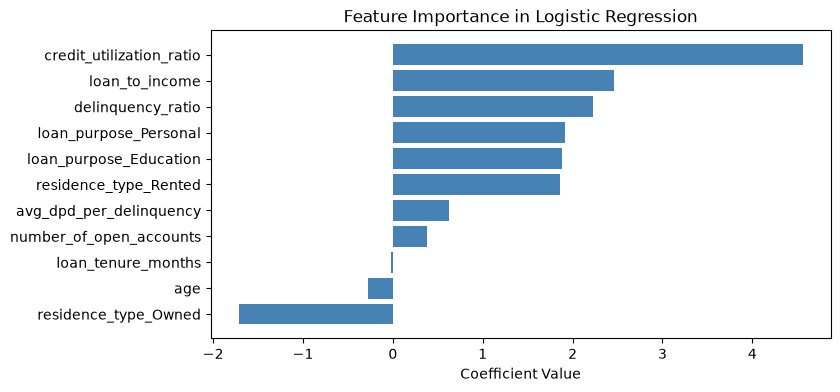

In [47]:
coef_df = pd.DataFrame(
    best_model.named_steps['classifier'].coef_[0],
    index=best_model.named_steps['classifier'].feature_names_in_,
    columns=['coefficients']
).sort_values(by='coefficients', ascending=False)

plt.figure(figsize=(8, 4))
plt.barh(coef_df.index, coef_df['coefficients'], color='steelblue')
plt.xlabel('Coefficient Value')
plt.title('Feature Importance in Logistic Regression')
plt.gca().invert_yaxis()
plt.show()

In [48]:
# Save best_model in trained_models dictionary

model = best_model

model_name = "model_logistic_regression_SMOTE_optuna_best_f2"

cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)


# Cross-Validation Metrics

f2 = make_scorer(fbeta_score, beta=2)

scoring_metrics = {
    'recall': 'recall',
    'f1_score': 'f1',
    'f1_macro': 'f1_macro',
    'f2_score': f2,
    'roc_auc': 'roc_auc',
    'pr_auc': 'average_precision'
}

cv_results = cross_validate(
    model,
    X_train,
    y_train,
    cv=cv_strategy,
    scoring=scoring_metrics
)

validation_recall   = cv_results['test_recall'].mean()
validation_f1       = cv_results['test_f1_score'].mean()
validation_f1_macro = cv_results['test_f1_macro'].mean()
validation_f2       = cv_results['test_f2_score'].mean()
validation_roc_auc  = cv_results['test_roc_auc'].mean()
validation_pr_auc   = cv_results['test_pr_auc'].mean()

# Out-Of-Fold Classification Report

oof_predictions = cross_val_predict(
    estimator=model,
    X=X_train,
    y=y_train,
    cv=cv_strategy
)

oof_report = classification_report(y_train, oof_predictions)

oof_report_dict = classification_report(y_train, oof_predictions, output_dict=True)


# Test Set Evaluation

test_classification_report, test_f2_score, test_roc_auc, test_pr_auc = evaluate_trained_model_pipeline(model)

test_classification_report_dict = classification_report(y_test, model.predict(X_test), output_dict=True)


# Store in trained_models dictionary

trained_models[model_name] = {

    "model": model,

    "params": study.best_params,

    "metrics": {

        # CV mean scores
        "cv_mean_recall": validation_recall,
        "cv_mean_f1": validation_f1,
        "cv_mean_f1_macro": validation_f1_macro,
        "cv_mean_f2": validation_f2,
        "cv_mean_roc_auc": validation_roc_auc,
        "cv_mean_pr_auc": validation_pr_auc,

        # Out-Of-Fold metrics
        "oof_class_0_precision": oof_report_dict['0']['precision'],
        "oof_class_0_recall": oof_report_dict['0']['recall'],
        "oof_class_0_f1-score": oof_report_dict['0']['f1-score'],

        "oof_class_1_precision": oof_report_dict['1']['precision'],
        "oof_class_1_recall": oof_report_dict['1']['recall'],
        "oof_class_1_f1-score": oof_report_dict['1']['f1-score'],

        "oof_accuracy": oof_report_dict['accuracy'],

        "oof_macro_avg_precision": oof_report_dict['macro avg']['precision'],
        "oof_macro_avg_recall": oof_report_dict['macro avg']['recall'],
        "oof_macro_avg_f1-score": oof_report_dict['macro avg']['f1-score'],

        # Test metrics
        "test_class_0_precision": test_classification_report_dict['0']['precision'],
        "test_class_0_recall": test_classification_report_dict['0']['recall'],
        "test_class_0_f1-score": test_classification_report_dict['0']['f1-score'],

        "test_class_1_precision": test_classification_report_dict['1']['precision'],
        "test_class_1_recall": test_classification_report_dict['1']['recall'],
        "test_class_1_f1-score": test_classification_report_dict['1']['f1-score'],

        "test_accuracy": test_classification_report_dict['accuracy'],

        "test_macro_avg_precision": test_classification_report_dict['macro avg']['precision'],
        "test_macro_avg_recall": test_classification_report_dict['macro avg']['recall'],
        "test_macro_avg_f1-score": test_classification_report_dict['macro avg']['f1-score'],

        "test_f2_score": test_f2_score,
        "test_roc_auc": test_roc_auc,
        "test_pr_auc": test_pr_auc
    },

    "artifacts": {
        "oof_report_text": oof_report,
        "test_report_text": test_classification_report
    }
}

In [49]:
list_of_metrics = [
    'oof_class_1_precision',
    'oof_class_1_recall',
    'test_class_1_precision',
    'test_class_1_recall'
]

compare_trained_models(list_of_metrics)

MODEL : model_logistic_regression_best_recall
oof_class_1_precision : 0.31	oof_class_1_recall : 0.99	test_class_1_precision : 0.32	test_class_1_recall : 0.99	

MODEL : model_logistic_regression_best_f1
oof_class_1_precision : 0.82	oof_class_1_recall : 0.71	test_class_1_precision : 0.82	test_class_1_recall : 0.72	

MODEL : model_logistic_regression_best_f1_macro
oof_class_1_precision : 0.82	oof_class_1_recall : 0.71	test_class_1_precision : 0.82	test_class_1_recall : 0.72	

MODEL : model_logistic_regression_best_f2
oof_class_1_precision : 0.52	oof_class_1_recall : 0.95	test_class_1_precision : 0.53	test_class_1_recall : 0.96	

MODEL : model_logistic_regression_best_roc_auc
oof_class_1_precision : 0.52	oof_class_1_recall : 0.95	test_class_1_precision : 0.53	test_class_1_recall : 0.95	

MODEL : model_logistic_regression_best_pr_auc
oof_class_1_precision : 0.82	oof_class_1_recall : 0.71	test_class_1_precision : 0.82	test_class_1_recall : 0.72	

MODEL : model_xgb_classifier_best_recall
oof_

In [117]:
# ----------------------------------------------------------------------------------------------
# MLflow and DagsHub
# ----------------------------------------------------------------------------------------------

# below line was for tracking experiments locally
# mlflow.set_tracking_uri("http://127.0.0.1:5000")

# below 2 lines are for tracking on DagsHub
mlflow.set_tracking_uri("https://dagshub.com/NavenduSingh17/credit-risk-scoring-mlflow.mlflow")
dagshub.init(repo_owner='NavenduSingh17', repo_name='credit-risk-scoring-mlflow', mlflow=True)

mlflow.set_experiment("credit-risk-scoring")

model_name = "model_logistic_regression_SMOTE_optuna_best_f2"
model = trained_models[model_name]['model']
params = model.get_params()     # getting params from named step 'classifier' will give C, not classifier__C
metrics = trained_models[model_name]['metrics']
artifacts = trained_models[model_name]['artifacts']

with mlflow.start_run(run_name=model_name, nested=True): 

    # Logging Hyperparameters
    params_to_be_tracked = [param for param in list(params.keys()) if 'classifier__' in param or 'resample__' in param]
    mlflow.log_params({k:v for k,v in params.items() if k in params_to_be_tracked})      # track resampling params too

    # Logging all Metrics
    mlflow.log_metrics(metrics)

    # To see classification report in artifacts
    mlflow.log_text(artifacts['oof_report_text'], artifact_file=f"oof_classification_report.txt")
    mlflow.log_text(artifacts['test_report_text'], artifact_file=f"test_classification_report.txt")

    # Logging Model
    need_to_pass_because_of_error = ['__main__.drop_generated_column', 'imblearn.over_sampling._smote.base.SMOTE', 'imblearn.pipeline.Pipeline', 'sklearn.metrics._dist_metrics.EuclideanDistance', 'sklearn.neighbors._kd_tree.KDTree']
    mlflow.sklearn.log_model(sk_model=model, name=model_name, skops_trusted_types=need_to_pass_because_of_error)

Initialized MLflow to track repo "NavenduSingh17/credit-risk-scoring-mlflow"

Repository NavenduSingh17/credit-risk-scoring-mlflow initialized!

2026/11/06 09:15:05 WARNING mlflow.utils.environment: Encountered an unexpected error while inferring pip requirements (model URI: /var/folders/l6/8b66p4052jxb1fc9rrzjy4mc0000gn/T/tmpqda5op99/model/model.skops, flavor: sklearn). Fall back to return ['scikit-learn==1.2.2', 'skops==0.16.0']. Set logging level to DEBUG to see the full traceback. 


🏃 View run model_logistic_regression_SMOTE_optuna_best_f2 at: https://dagshub.com/NavenduSingh17/credit-risk-scoring-mlflow.mlflow/#/experiments/0/runs/8fc2a2eb21754fe6b2bade8a39019845
🧪 View experiment at: https://dagshub.com/NavenduSingh17/credit-risk-scoring-mlflow.mlflow/#/experiments/0


In [56]:
# study.__dict__
# dir(study)

---

    Never Resample the Test Set

    fit_resample is only used on X_train and y_train

    If you resample your test set, you will leak synthetic data into your evaluation, giving you fake, overly optimistic accuracy scores.

    If you are using a scikit-learn Pipeline, standard scikit-learn transformers cannot handle resampling because they don't alter the y target array during fit or transform.
    To fix this, you must use the Pipeline class from imblearn.pipeline instead of sklearn.pipeline. It behaves exactly the same way, but it knows how to handle resampling techniques like SMOTE and SMOTE-Tomek safely during cross-validation without data leakage.

    • Automatic Test Safeguard: The imblearn pipeline is smart. When you call .fit(), it applies SMOTE/SMOTE-Tomek to balance your training data. When you call .predict(), it automatically bypasses the resampling step. Your test data stays completely untouched and raw.

    • GridSearch Safe: If you pass these pipelines into GridSearchCV, it will properly resample only the training folds during cross-validation, completely eliminating data leakage.

    Swap the standard scikit-learn Pipeline import for imblearn.pipeline.Pipeline.

    Inject your chosen resampling step right in the middle—after the preprocessor transforms your features, but before the classifier trains on them.

---

---

##### __Attempt 4__

`ATTEMPTED`

- `Handled Class Imbalance : SMOTE (over-sampling minority class)`

- `XGB Classifier`

- `Optuna for Hyperparameter Tuning`

---

> `Quick check SMOTE with XGB Classifier`

In [38]:
model = ImbPipeline([                       # Using ImbPipeline instead of sklearn Pipeline, so that TEST set doesn't get re-smpled
    *PREPROCESSOR.steps,                    # imblearn problem : This inserts the individual steps of PREPROCESSOR directly
    ('resample', SMOTE(random_state=42)),
    ('classifier', XGBClassifier())
])

cross_validate_model_pipeline(model)

model.fit(X_train, y_train)
print_evaluate_trained_model_pipeline(model)

----------------------------------------------------------------------------------------------------
Cross-Validation Performance (Train Dataset) : XGBClassifier
    Mean Recall : 0.83
    Mean F1 Score : 0.77
    Mean F1 Score (macro avg) : 0.87
    Mean F2 Score : 0.80
    Mean AUC (ROC) : 0.98
    Mean AUC (PR) : 0.87

Out-Of-Fold Classification Report (Train Dataset Split) : 
              precision    recall  f1-score   support

           0       0.98      0.97      0.98     31986
           1       0.72      0.83      0.77      3008

    accuracy                           0.96     34994
   macro avg       0.85      0.90      0.87     34994
weighted avg       0.96      0.96      0.96     34994

Pooled F2 Score : 0.80
Pooled AUC (ROC) : 0.98
Pooled AUC (PR) : 0.87
----------------------------------------------------------------------------------------------------
Classification Report for XGBClassifier (on Test Set) :
              precision    recall  f1-score   support

        

---

> `Optuna`

- We will maximise f2-score with Optuna

- Optuna provides only best_params, not best_estimator
- We have to create a model with best_params and then fit it using X_train, y_train

In [53]:
def objective(trial):
    params = {
        'objective'         : 'binary:logistic',
        'eval_metric'       : 'logloss',
        'verbosity'         : 0,
        'booster'           : 'gbtree',
        'lambda'            : trial.suggest_float('lambda', 1e-3, 10.0, log=True),
        'alpha'             : trial.suggest_float('alpha', 1e-3, 10.0, log=True),
        'subsample'         : trial.suggest_float('subsample', 0.4, 1.0),
        'colsample_bytree'  : trial.suggest_float('colsample_bytree', 0.4, 1.0),
        'max_depth'         : trial.suggest_int('max_depth', 3, 10),
        'eta'               : trial.suggest_float('eta', 0.01, 0.3),
        'gamma'             : trial.suggest_float('gamma', 0, 10),
        'scale_pos_weight'  : trial.suggest_float('scale_pos_weight', 1, 10),
        'min_child_weight'  : trial.suggest_int('min_child_weight', 1, 10),
        'max_delta_step'    : trial.suggest_int('max_delta_step', 0, 10)
    }

    model = ImbPipeline([                       # Using ImbPipeline instead of sklearn Pipeline, so that TEST set doesn't get re-smpled
        *PREPROCESSOR.steps,                    # imblearn problem : This inserts the individual steps of PREPROCESSOR directly
        ('resample', SMOTE(random_state=42)),
        ('classifier', XGBClassifier(**params, random_state=42))
    ])

    cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

    f2_score = make_scorer(fbeta_score, beta=2)

    scores = cross_val_score(
        model,
        X_train,
        y_train, 
        cv=cv_strategy,
        scoring=f2_score,
        n_jobs=-1
    )

    return scores.mean()


study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=42))  # sampler set for reproducibility, like how we use random_state

study.optimize(objective, n_trials=50)

print("\n--- Optuna Optimisation Completed ---")
print("Best Mean F2 Score from Cross Validation    : ", study.best_value)
print("Best Hyperarameters  :")
for k,v in study.best_params.items():
    print(f"    {k} : {v}")

[I 2026-11-05 18:17:16,715] A new study created in memory with name: no-name-d03fb9a6-1121-4fed-98b2-edb3eb5bfc58
[I 2026-11-05 18:17:19,164] Trial 0 finished with value: 0.7424256176616753 and parameters: {'lambda': 0.03148911647956861, 'alpha': 6.351221010640703, 'subsample': 0.839196365086843, 'colsample_bytree': 0.759195090518222, 'max_depth': 4, 'eta': 0.055238410897498764, 'gamma': 0.5808361216819946, 'scale_pos_weight': 8.795585311974417, 'min_child_weight': 7, 'max_delta_step': 7}. Best is trial 0 with value: 0.7424256176616753.
[I 2026-11-05 18:17:21,227] Trial 1 finished with value: 0.7257926394458754 and parameters: {'lambda': 0.0012087541473056963, 'alpha': 7.579479953348009, 'subsample': 0.899465584480253, 'colsample_bytree': 0.5274034664069657, 'max_depth': 4, 'eta': 0.06318730785749581, 'gamma': 3.0424224295953772, 'scale_pos_weight': 5.72280788469014, 'min_child_weight': 5, 'max_delta_step': 3}. Best is trial 0 with value: 0.7424256176616753.
[I 2026-11-05 18:17:22,952]


--- Optuna Optimisation Completed ---
Best Mean F2 Score from Cross Validation    :  0.8536328775819649
Best Hyperarameters  :
    lambda : 0.36977950564172973
    alpha : 0.3608705753146192
    subsample : 0.4329050595467896
    colsample_bytree : 0.9541570695467219
    max_depth : 4
    eta : 0.20284092746151342
    gamma : 9.602523926806075
    scale_pos_weight : 1.298761753913124
    min_child_weight : 4
    max_delta_step : 2


In [54]:
best_model = ImbPipeline([              
    *PREPROCESSOR.steps,                    # imblearn problem : This inserts the individual steps of PREPROCESSOR directly
    ('resample', SMOTE(random_state=42)),
    ('classifier', XGBClassifier(**study.best_params, random_state=42))
])

cross_validate_model_pipeline(best_model)

best_model.fit(X_train, y_train)
print_evaluate_trained_model_pipeline(best_model)

----------------------------------------------------------------------------------------------------
Cross-Validation Performance (Train Dataset) : XGBClassifier
    Mean Recall : 0.94
    Mean F1 Score : 0.75
    Mean F1 Score (macro avg) : 0.86
    Mean F2 Score : 0.85
    Mean AUC (ROC) : 0.99
    Mean AUC (PR) : 0.88

Out-Of-Fold Classification Report (Train Dataset Split) : 
              precision    recall  f1-score   support

           0       0.99      0.95      0.97     31986
           1       0.62      0.94      0.75      3008

    accuracy                           0.95     34994
   macro avg       0.81      0.94      0.86     34994
weighted avg       0.96      0.95      0.95     34994

Pooled F2 Score : 0.85
Pooled AUC (ROC) : 0.99
Pooled AUC (PR) : 0.88
----------------------------------------------------------------------------------------------------
Classification Report for XGBClassifier (on Test Set) :
              precision    recall  f1-score   support

        

In [ ]:
# Out-Of-Fold Classification Report (Train Dataset Split) : 
#               precision    recall  f1-score   support

#            0       0.98      0.97      0.98     31986
#            1       0.72      0.83      0.77      3008

#     accuracy                           0.96     34994
#    macro avg       0.85      0.90      0.87     34994
# weighted avg       0.96      0.96      0.96     34994

# Pooled F2 Score : 0.80
# Pooled AUC (ROC) : 0.98
# Pooled AUC (PR) : 0.87

`Compared Out-Of-Fold Classification Reports : `

- `Using Optuna for maximizing F2 Score has significantly improved recall, as compared to [XGBClassifier + SMOTE (without hyperparameter tuning)]`

- `precision (for class_1) dropped though`

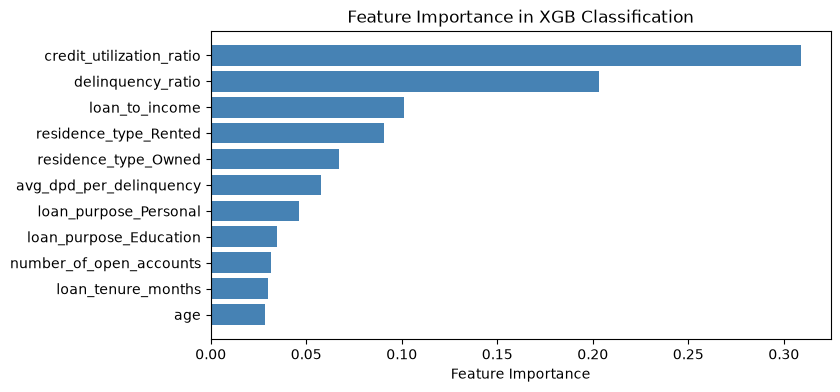

In [55]:
feature_importance_df = pd.DataFrame(
    best_model.named_steps['classifier'].feature_importances_,
    index=best_model.named_steps['classifier'].feature_names_in_,
    columns=['feature_importance']
    ).sort_values(by='feature_importance', ascending=False)

plt.figure(figsize=(8, 4))
plt.barh(feature_importance_df.index, feature_importance_df['feature_importance'], color='steelblue')
plt.xlabel('Feature Importance')
plt.title('Feature Importance in XGB Classification')
plt.gca().invert_yaxis()
plt.show()

In [56]:
# Save best_model in trained_models dictionary

model = best_model

model_name = "model_xgb_classifier_SMOTE_optuna_best_f2"

cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)


# Cross-Validation Metrics

f2 = make_scorer(fbeta_score, beta=2)

scoring_metrics = {
    'recall': 'recall',
    'f1_score': 'f1',
    'f1_macro': 'f1_macro',
    'f2_score': f2,
    'roc_auc': 'roc_auc',
    'pr_auc': 'average_precision'
}

cv_results = cross_validate(
    model,
    X_train,
    y_train,
    cv=cv_strategy,
    scoring=scoring_metrics
)

validation_recall   = cv_results['test_recall'].mean()
validation_f1       = cv_results['test_f1_score'].mean()
validation_f1_macro = cv_results['test_f1_macro'].mean()
validation_f2       = cv_results['test_f2_score'].mean()
validation_roc_auc  = cv_results['test_roc_auc'].mean()
validation_pr_auc   = cv_results['test_pr_auc'].mean()

# Out-Of-Fold Classification Report

oof_predictions = cross_val_predict(
    estimator=model,
    X=X_train,
    y=y_train,
    cv=cv_strategy
)

oof_report = classification_report(y_train, oof_predictions)

oof_report_dict = classification_report(y_train, oof_predictions, output_dict=True)


# Test Set Evaluation

test_classification_report, test_f2_score, test_roc_auc, test_pr_auc = evaluate_trained_model_pipeline(model)

test_classification_report_dict = classification_report(y_test, model.predict(X_test), output_dict=True)


# Store in trained_models dictionary

trained_models[model_name] = {

    "model": model,

    "params": study.best_params,

    "metrics": {

        # CV mean scores
        "cv_mean_recall": validation_recall,
        "cv_mean_f1": validation_f1,
        "cv_mean_f1_macro": validation_f1_macro,
        "cv_mean_f2": validation_f2,
        "cv_mean_roc_auc": validation_roc_auc,
        "cv_mean_pr_auc": validation_pr_auc,

        # Out-Of-Fold metrics
        "oof_class_0_precision": oof_report_dict['0']['precision'],
        "oof_class_0_recall": oof_report_dict['0']['recall'],
        "oof_class_0_f1-score": oof_report_dict['0']['f1-score'],

        "oof_class_1_precision": oof_report_dict['1']['precision'],
        "oof_class_1_recall": oof_report_dict['1']['recall'],
        "oof_class_1_f1-score": oof_report_dict['1']['f1-score'],

        "oof_accuracy": oof_report_dict['accuracy'],

        "oof_macro_avg_precision": oof_report_dict['macro avg']['precision'],
        "oof_macro_avg_recall": oof_report_dict['macro avg']['recall'],
        "oof_macro_avg_f1-score": oof_report_dict['macro avg']['f1-score'],

        # Test metrics
        "test_class_0_precision": test_classification_report_dict['0']['precision'],
        "test_class_0_recall": test_classification_report_dict['0']['recall'],
        "test_class_0_f1-score": test_classification_report_dict['0']['f1-score'],

        "test_class_1_precision": test_classification_report_dict['1']['precision'],
        "test_class_1_recall": test_classification_report_dict['1']['recall'],
        "test_class_1_f1-score": test_classification_report_dict['1']['f1-score'],

        "test_accuracy": test_classification_report_dict['accuracy'],

        "test_macro_avg_precision": test_classification_report_dict['macro avg']['precision'],
        "test_macro_avg_recall": test_classification_report_dict['macro avg']['recall'],
        "test_macro_avg_f1-score": test_classification_report_dict['macro avg']['f1-score'],

        "test_f2_score": test_f2_score,
        "test_roc_auc": test_roc_auc,
        "test_pr_auc": test_pr_auc
    },

    "artifacts": {
        "oof_report_text": oof_report,
        "test_report_text": test_classification_report
    }
}

In [57]:
list_of_metrics = [
    'oof_class_1_precision',
    'oof_class_1_recall',
    'test_class_1_precision',
    'test_class_1_recall'
]

compare_trained_models(list_of_metrics)

MODEL : model_logistic_regression_best_recall
oof_class_1_precision : 0.31	oof_class_1_recall : 0.99	test_class_1_precision : 0.32	test_class_1_recall : 0.99	

MODEL : model_logistic_regression_best_f1
oof_class_1_precision : 0.82	oof_class_1_recall : 0.71	test_class_1_precision : 0.82	test_class_1_recall : 0.72	

MODEL : model_logistic_regression_best_f1_macro
oof_class_1_precision : 0.82	oof_class_1_recall : 0.71	test_class_1_precision : 0.82	test_class_1_recall : 0.72	

MODEL : model_logistic_regression_best_f2
oof_class_1_precision : 0.52	oof_class_1_recall : 0.95	test_class_1_precision : 0.53	test_class_1_recall : 0.96	

MODEL : model_logistic_regression_best_roc_auc
oof_class_1_precision : 0.52	oof_class_1_recall : 0.95	test_class_1_precision : 0.53	test_class_1_recall : 0.95	

MODEL : model_logistic_regression_best_pr_auc
oof_class_1_precision : 0.82	oof_class_1_recall : 0.71	test_class_1_precision : 0.82	test_class_1_recall : 0.72	

MODEL : model_xgb_classifier_best_recall
oof_

In [118]:
# ----------------------------------------------------------------------------------------------
# MLflow and DagsHub
# ----------------------------------------------------------------------------------------------

# below line was for tracking experiments locally
# mlflow.set_tracking_uri("http://127.0.0.1:5000")

# below 2 lines are for tracking on DagsHub
mlflow.set_tracking_uri("https://dagshub.com/NavenduSingh17/credit-risk-scoring-mlflow.mlflow")
dagshub.init(repo_owner='NavenduSingh17', repo_name='credit-risk-scoring-mlflow', mlflow=True)

mlflow.set_experiment("credit-risk-scoring")

model_name = "model_xgb_classifier_SMOTE_optuna_best_f2"
model = trained_models[model_name]['model']
params = model.get_params()     # getting params from named step 'classifier' will give C, not classifier__C
metrics = trained_models[model_name]['metrics']
artifacts = trained_models[model_name]['artifacts']

with mlflow.start_run(run_name=model_name, nested=True): 

    # Logging Hyperparameters
    params_to_be_tracked = [param for param in list(params.keys()) if 'classifier__' in param or 'resample__' in param]
    mlflow.log_params({k:v for k,v in params.items() if k in params_to_be_tracked})      # track resampling params too

    # Logging all Metrics
    mlflow.log_metrics(metrics)

    # To see classification report in artifacts
    mlflow.log_text(artifacts['oof_report_text'], artifact_file=f"oof_classification_report.txt")
    mlflow.log_text(artifacts['test_report_text'], artifact_file=f"test_classification_report.txt")

    # Logging Model
    need_to_pass_because_of_error=['__main__.drop_generated_column', 'imblearn.over_sampling._smote.base.SMOTE', 'imblearn.pipeline.Pipeline', 'sklearn.metrics._dist_metrics.EuclideanDistance', 'sklearn.neighbors._kd_tree.KDTree', 'xgboost.core.Booster', 'xgboost.sklearn.XGBClassifier']
    mlflow.sklearn.log_model(sk_model=model, name=model_name, skops_trusted_types=need_to_pass_because_of_error)

Initialized MLflow to track repo "NavenduSingh17/credit-risk-scoring-mlflow"

Repository NavenduSingh17/credit-risk-scoring-mlflow initialized!

2026/11/06 09:16:00 WARNING mlflow.utils.environment: Encountered an unexpected error while inferring pip requirements (model URI: /var/folders/l6/8b66p4052jxb1fc9rrzjy4mc0000gn/T/tmphu_xzb0f/model/model.skops, flavor: sklearn). Fall back to return ['scikit-learn==1.2.2', 'skops==0.16.0']. Set logging level to DEBUG to see the full traceback. 


🏃 View run model_xgb_classifier_SMOTE_optuna_best_f2 at: https://dagshub.com/NavenduSingh17/credit-risk-scoring-mlflow.mlflow/#/experiments/0/runs/d7d1aa603fa94a06a329bd3c5d009fef
🧪 View experiment at: https://dagshub.com/NavenduSingh17/credit-risk-scoring-mlflow.mlflow/#/experiments/0


---

#### `Business Evaluation`


- Business requirements    
    - Recall should be greater than 90%
    - Since the loan officer will anyway review the application, low Precision is alright; it should be greater than 50%

- Let's go with [Logistic Regression + SMOTE]

- Logistic Regression has better interpretability and explainability (via model coefficients) for BRE (Business Rule Engine) (must easily prove to auditors exactly how the model works).
XGB has an 8 percent precision advantage but it doesn't tell the direction of the relationship, we need to use SHAP for that.

- Evaluate Gini Coefficient and KS Statistic

- Discuss with Client : We can tweak (increase) threshold value for classification (predict_proba) a bit - it'll decrease the recall a little (while still keeping it above 90%) but increase precision

##### __The chosen model__

In [120]:
for x in trained_models.keys():
    print(x)

model_logistic_regression_best_recall
model_logistic_regression_best_f1
model_logistic_regression_best_f1_macro
model_logistic_regression_best_f2
model_logistic_regression_best_roc_auc
model_logistic_regression_best_pr_auc
model_xgb_classifier_best_recall
model_xgb_classifier_best_f1
model_xgb_classifier_best_f1_macro
model_xgb_classifier_best_f2
model_xgb_classifier_best_roc_auc
model_xgb_classifier_best_pr_auc
model_logistic_regression_SMOTE_optuna_best_f2
model_xgb_classifier_SMOTE_optuna_best_f2


`Getting the Trained (Fitted) Model`

In [121]:
# This is a Trained (Fitted) Model

FINAL_MODEL = trained_models['model_logistic_regression_SMOTE_optuna_best_f2']['model']

model

Pipeline(steps=[('transform_features',
                 ColumnTransformer(transformers=[('scaler', StandardScaler(),
                                                  ['number_of_open_accounts',
                                                   'credit_utilization_ratio',
                                                   'age', 'loan_tenure_months',
                                                   'loan_to_income',
                                                   'delinquency_ratio',
                                                   'avg_dpd_per_delinquency']),
                                                 ('encoder',
                                                  OneHotEncoder(drop='first',
                                                                sparse_output=False),
                                                  ['residence_type',
                                                   'loan_purpose'])],
                                   verbose_feat...
                               feature_types=None, feature_weights=None,
                               gamma=9.602523926806075, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None,
                               lambda=0.36977950564172973, learning_rate=None,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=2,
                               max_depth=4, max_leaves=None, min_child_weight=4,
                               missing=nan, monotone_constraints=None,
                               multi_strategy=None, ...))])

In [ ]:
# # We can also pull the model from MLflow

# # run_id and artifact path
# model_uri = "runs:/142da68d184d494689d656ae13140664/model_logistic_regression_SMOTE_optuna_best_f2"

# FINAL_MODEL = mlflow.pyfunc.load_model(model_uri)

# FINAL_MODEL.predict(X_test)

`Threshold Tuning can be done using TunedThresholdClassifierCV`

In [ ]:
def threshold_evaluation(model, threshold):
    """
    To check model performance at different thresholds for classification
    """
    temp_df = pd.DataFrame()
    temp_df['actual'] = y_test
    temp_df['predicted_proba'] = model.predict_proba(X_test)[:, 1]

    temp_df['predicted'] = 0
    temp_df.loc[temp_df['predicted_proba']>threshold, 'predicted'] = 1
    
    print(classification_report(temp_df['actual'], temp_df['predicted']))

In [ ]:
# Function to find best threshold from ROC (CodeBasics -> ML Course -> ROC Lecture)

`SHAP analysis can be done`

##### __ROC AUC, Gini Coefficient__

ROC AUC :  0.9829912464565332
Gini Coefficient :  0.9659824929130665




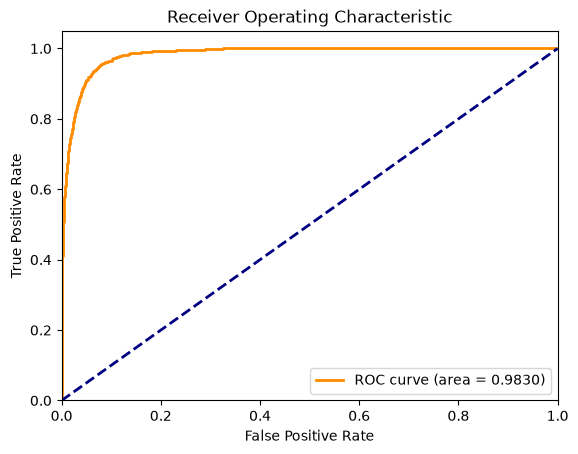

In [122]:
y_pred_proba = FINAL_MODEL.predict_proba(X_test)[:, 1]
fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba)
print("ROC AUC : ", auc(fpr, tpr))
print("Gini Coefficient : ", 2 * auc(fpr, tpr) - 1)
print('\n')

# PLOTTING THE ROC CURVE
plt.figure()
plt.plot(fpr, tpr, color='darkorange', lw=2, label='ROC curve (area = %0.4f)' % auc(fpr, tpr))
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic')
plt.legend(loc="lower right")
plt.show()

- 0.97 Gini Coefficient shows that the model is good at distinguishing between the classes
- The Gini coefficient ranges from -1 to 1, where a value closer to 1 signifies a perfect model, 0 indicates a model with no discriminative power, and -1 signifies a perfectly incorrect model.

##### __Rank ordering, KS statistic__

In [166]:
y_pred_proba = FINAL_MODEL.predict_proba(X_test)[:, 1]

df_eval = pd.DataFrame()
df_eval['truth'] = y_test
df_eval['predicted_probability'] = y_pred_proba

# Handle heavy probability ties at 0 using rank-based qcut
# This forces exactly 10% of records into each decile bucket
# df_eval['decile'] = pd.qcut(
#   df_eval['predicted_probability'].rank(method='first'), 
#   q=10, 
#   labels=False)

df_eval['decile'] = pd.qcut(
    df_eval['predicted_probability'], 
    q=10, 
    labels=False, 
    duplicates='drop')

df_eval

,truth,predicted_probability,decile
8107,0,0.00,5
49270,1,1.00,9
17748,0,0.00,2
46217,0,0.00,4
4105,0,0.46,8
...,...,...,...
570,0,0.00,3
9907,0,0.00,2
31004,0,0.00,4
24362,1,0.61,8


- Non-Events : Customers who don't default (good)

- Events : Customers who default (bad)

In [167]:
# df_decile = df_eval.groupby('decile').agg(
#     min_prob = ('predicted_probability', 'min'),
#     max_prob = ('predicted_probability', 'max'),
#     events = ('truth', 'sum'),
#     non_events = ('truth', lambda x : (x.count() - x.sum()))
# ).reset_index()
# df_decile


# df_decile = df_eval.groupby('decile').agg(
#     min_prob=('predicted_probability', 'min'),
#     max_prob=('predicted_probability', 'max'),
#     events=('truth', 'sum'),
#     total_count=('truth', 'count') 
# ).reset_index()
# df_decile['non_events'] = df_decile['total_count'] - df_decile['events']
# df_decile = df_decile.drop(columns=['total_count'])


df_decile = df_eval.groupby('decile').agg({
    'predicted_probability' : ['min', 'max'],
    'truth' : ['sum', lambda x:(x.count() - x.sum())]
}).reset_index()

df_decile.columns = ['decile', 'min_prob', 'max_prob', 'events', 'non_events']

df_decile

,decile,min_prob,max_prob,events,non_events
0,0,0.00,0.00,0,1500
1,1,0.00,0.00,0,1500
2,2,0.00,0.00,0,1500
3,3,0.00,0.00,0,1499
4,4,0.00,0.00,0,1500
5,5,0.00,0.01,0,1500
6,6,0.01,0.03,7,1492
7,7,0.03,0.22,17,1483
8,8,0.22,0.81,190,1310
9,9,0.81,1.00,1075,425


In [168]:
df_decile = df_decile.sort_values(by='decile', ascending=False).reset_index(drop=True)

df_decile['event_rate'] = (df_decile['events'] * 100) / (df_decile['events'] + df_decile['non_events'])
df_decile['non_event_rate'] = (df_decile['non_events'] * 100) / (df_decile['events'] + df_decile['non_events'])

df_decile['cum_events'] =  df_decile['events'].cumsum()
df_decile['cum_non_events'] =  df_decile['non_events'].cumsum()

df_decile['cum_event_rate'] = (df_decile['cum_events'] * 100) / df_decile['events'].sum()
df_decile['cum_non_event_rate'] = (df_decile['cum_non_events'] * 100) / df_decile['non_events'].sum()

df_decile['KS_separation'] = abs(df_decile['cum_event_rate'] - df_decile['cum_non_event_rate'])

df_decile

,decile,min_prob,max_prob,events,non_events,event_rate,non_event_rate,cum_events,cum_non_events,cum_event_rate,cum_non_event_rate,KS_separation
0,9,0.81,1.00,1075,425,71.67,28.33,1075,425,83.40,3.10,80.30
1,8,0.22,0.81,190,1310,12.67,87.33,1265,1735,98.14,12.66,85.48
2,7,0.03,0.22,17,1483,1.13,98.87,1282,3218,99.46,23.47,75.98
3,6,0.01,0.03,7,1492,0.47,99.53,1289,4710,100.00,34.36,65.64
4,5,0.00,0.01,0,1500,0.00,100.00,1289,6210,100.00,45.30,54.70
5,4,0.00,0.00,0,1500,0.00,100.00,1289,7710,100.00,56.24,43.76
6,3,0.00,0.00,0,1499,0.00,100.00,1289,9209,100.00,67.17,32.83
7,2,0.00,0.00,0,1500,0.00,100.00,1289,10709,100.00,78.12,21.88
8,1,0.00,0.00,0,1500,0.00,100.00,1289,12209,100.00,89.06,10.94
9,0,0.00,0.00,0,1500,0.00,100.00,1289,13709,100.00,100.00,0.00


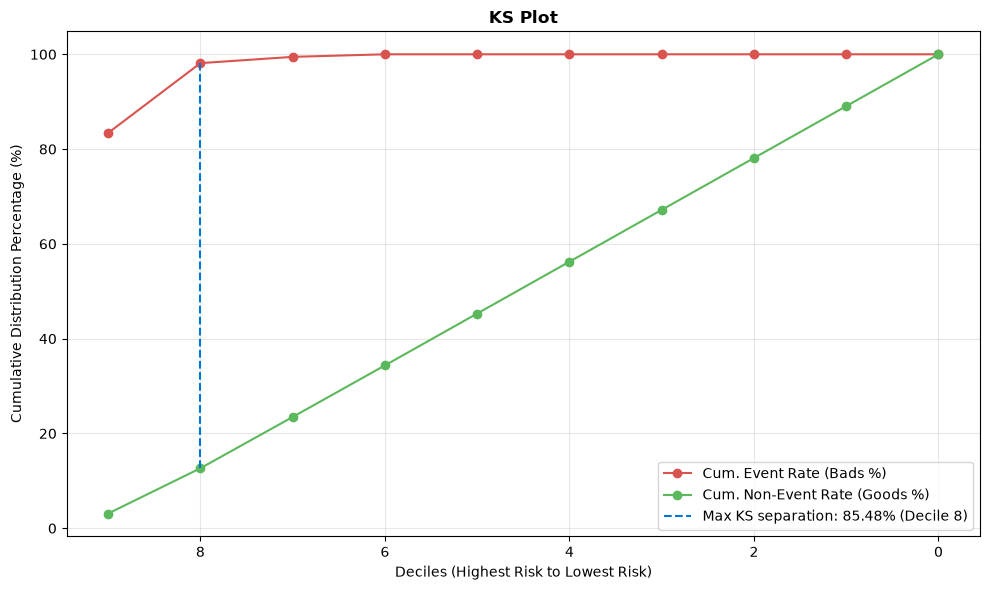

In [ ]:
# KS Plot (I generated this code using Google AI Mode)

plt.figure(figsize=(10, 6), dpi=100)
plt.plot(df_decile['decile'], df_decile['cum_event_rate'], marker='o', color='#d9534f', label='Cum. Event Rate (Bads %)')
# Just typing the hex code makes the colour picker appear, but only if you are using an editor that natively supports it (like VS Code)
plt.plot(df_decile['decile'], df_decile['cum_non_event_rate'], marker='o', color='#5cb85c', label='Cum. Non-Event Rate (Goods %)')

# Dynamically locate the max KS_separation row for charting annotations
max_ks_idx = df_decile['KS_separation'].idxmax()
max_ks_row = df_decile.loc[max_ks_idx]

plt.vlines(
    x=max_ks_row['decile'], 
    ymin=max_ks_row['cum_non_event_rate'], 
    ymax=max_ks_row['cum_event_rate'], 
    colors='#0275d8', 
    linestyles='dashed', 
    label=f"Max KS separation: {max_ks_row['KS_separation']:.2f}% (Decile {int(max_ks_row['decile'])})"
)

plt.title('KS Plot', fontsize=12, weight='bold')
plt.xlabel('Deciles (Highest Risk to Lowest Risk)')
plt.ylabel('Cumulative Distribution Percentage (%)')
plt.gca().invert_xaxis()
plt.legend(loc='lower right')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

The Kolmogorov-Smirnov (KS) statistic combined with rank ordering is a popular metric used to evaluate how well a classification model (such as a credit scoring or default-prediction model) separates positive events (e.g., defaulters, bads) from negative events (e.g., non-defaulters, goods).

If maximum KS separation occurs in top 3 decile and scores above 40%, it is considered a good predictive model

KS score (Maximum KS Separation) > 0.4 (40%) means the model has a strong discrimination power

If the maximum KS separation occurs early in the distribution, i.e., top 3 deciles, it means it's a strong rank-ordered model

For our model :

- Event Rate decreases from the Top Decile to the Bottom Decile
- This shows Monotonic Rank Ordering

- Maximum KS Separation (KS score) = 85.48% (0.8548)
- It is more than 40% : This shows our model performs well

- Max KS separation occured in Decile 8 (2nd from Top)

- This shows it's a good predictive model

In [ ]:
# THis is the EXACT KS Statistic

from scipy.stats import ks_2samp

ks_statistic, ks_pvalue = ks_2samp(
    y_pred_proba[y_test == 1],
    y_pred_proba[y_test == 0]
)

print("KS Statistic:", ks_statistic)

KS Statistic: 0.8758124444248768


#### `Model Export`

In [ ]:
FINAL_MODEL.named_steps.keys()

dict_keys(['transform_features', 'drop_specific_column', 'resample', 'classifier'])

`We can remove the 'resample' step before exporting or let it stay`

`imblearn pipeline knows that it shouldn't resample when .predict() or .prdict_proba() is called`

In [ ]:
joblib.dump(FINAL_MODEL, "../artifacts/classifier.joblib")

['../artifacts/classifier.joblib']